# Phase I · What fools the detectors?

**Black-box behaviour of the plain CNN and the fine-tuned ResNet18 on CIFAKE**

Phase I treats both trained detectors as closed boxes: an image goes in, one **REAL logit** comes out (positive → REAL, negative → FAKE, threshold 0 ⇔ P = 0.5). Nothing in this notebook reads activations, gradients or weights. Every pattern is computed on **all 10,000 validation images** (5,000 REAL, 5,000 FAKE) of our audited split, or on all 5,000 images of one label; galleries are illustrations chosen by a stated rule.

**What we already knew.** The model notebooks showed that blur and a small resize collapse fake detection, while JPEG and noise raise false alarms. The training-data exploration (`01_training_data_exploration.ipynb`) showed that FAKE training images are sharper than REAL ones. This notebook asks *why the behaviour looks like that* and tests the answer with inputs we designed ourselves.

| | Question | Visualization (lecture) |
|---|---|---|
| 1 | Do the clean-image errors follow the sharpness difference found in the training data? | Error rate by sharpness decile with the data distribution (training data as a hypothesis source) |
| 2 | Is there one rule behind JPEG, blur, resize and noise? | "Sharpness dial": every edit family on one sharpness axis, plus **new counterfactual sharpening** (L03 trajectories) |
| 3 | Do the edits destroy information or shift confidence? | Score distributions and ROC-AUC per edit strength |
| 4 | Does every image respond the same way? | Centered ICE curves with the PDP (L04) |
| 5 | Which fakes survive blur, and why? | Object-class slope chart + **counterfactual desaturation** + gallery |
| 6 | What distinguishes the survivors from the fooled fakes? | t-SNE/PCA projection of image descriptors, k-means groups and their profiles (L02, L03) |
| 7 | Do the two detectors fail on the same images? | Logit-vs-logit density and error overlap against chance |
| 8 | What do we carry into Phase II? | Findings and open questions |

**Inputs.** 29 conditions per image: the original, the 16 edits used in both model notebooks (identical code, seeds and parameters), and 12 new counterfactual edits: unsharp-mask sharpening (radius 1 px, 25–200 %), blur 0.6 px followed by sharpening, colour saturation ×0.5–×1.5, and blur 0.6 px followed by desaturation. The object class (airplane … truck) is read from the CIFAKE filename suffix, which encodes the CIFAR-10 class for both labels (5,000 per class and label in the training folder; checked visually).

**Descriptors.** All image statistics are model-independent and computed on the native 32×32 pixels: brightness, contrast and saturation as in the EDA notebook; *sharpness* = log₁₀ variance of the 4-neighbour Laplacian of luma on the 30×30 interior (the EDA definition); *high-frequency share* = fraction of Hann-windowed, DC-free luma power at radius ≥ 0.25 cycles/pixel; *centre/border sharpness* = log₁₀ ratio of Laplacian variance in the central 16×16 versus the surrounding ring (a rough object-versus-background proxy); and eight radial spectral band shares.


## 0. Setup and data

    Run the cells in order. We use the saved 10,000-image bundle by default.
    Each section separates the preparation, plotting and interpretation.
    The written findings describe the bundled run; if you rebuild it with a different model,
    check those findings against the new plots before reusing them.


In [1]:
# Imports for image statistics and the plots below.
from pathlib import Path
from io import BytesIO
import csv
import hashlib
import json
import re
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm, LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
import matplotlib.patheffects as pe
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score

get_ipython().run_line_magic("matplotlib", "inline")
plt.ioff()  # Show a figure only after all its panels have been drawn.


In [2]:
# Find the repository and choose whether to rebuild the saved data.
# The notebook lives in phase1/; data, runs and weights live at the repository root.
ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "team-info.json").exists():
        ROOT = candidate
        break

RECOMPUTE = False  # Rebuild the bundle from local data and weights (about two minutes on a GPU).
SAVE_FIGURES = False  # Also write PNG copies to results/phase1_comparison/.
BUNDLE_PATH = ROOT / "phase1" / "data" / "phase1_behaviour_bundle.npz"
BUNDLE_SHA256 = "b89ae7db595c93ba42d9b1e0ad11db82b62623f067d59cbb0a63d77332c0cdfe"
FIGURE_DIR = ROOT / "results" / "phase1_comparison"


In [3]:
# Keep label colours the same as in the other Phase I notebooks.
# Colours: REAL/FAKE keep the Okabe-Ito pair used in every team notebook; edit families use a
# separately validated categorical set and are always direct-labelled.
REAL_C, FAKE_C = "#0072B2", "#D55E00"
FAMILY_COLORS = {"JPEG": "#6250d6", "Blur": "#1baf7a", "Resize": "#eda100", "Noise": "#e87ba4", "Sharpen": "#008300"}
OUTCOME_COLORS = {"still FAKE for both": FAKE_C, "models disagree": "#eda100", "REAL for both (fooled)": REAL_C}
INK, MUTED = "#222222", "#6b6b6b"
SEQ_PURPLE = LinearSegmentedColormap.from_list("seq_purple", ["#d9d3f5", "#6250d6", "#241a6b"])
SEQ_GREEN = LinearSegmentedColormap.from_list("seq_green", ["#cfe9cf", "#2f9a2f", "#0b4a0b"])
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.15,
        "axes.axisbelow": True,
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
        "font.size": 10,
    }
)


In [4]:
# Reuse these small helpers when showing a plot or printing a percentage.
def finish(fig, name):
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"


print(f"Repository root found; this notebook runs from {Path.cwd().resolve().relative_to(ROOT)}/")


Repository root found; this notebook runs from phase1/


**The image edits.** The galleries below need these definitions to show what an edit
    looks like. The optional rebuild uses exactly the same definitions for model inference.
    Each image keeps its identity throughout the experiment.


In [5]:
# List the original 17 conditions and the 12 added sharpening/colour tests.
from PIL import Image, ImageEnhance, ImageFilter

PROBE_SEED = 2026
OBJECT_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]


def object_index(path):
    """CIFAKE suffix: no suffix = airplane, (2) = automobile, ..., (10) = truck."""
    match = re.search(r"\((\d+)\)", Path(path).name)
    return 0 if match is None else int(match.group(1)) - 1


CONDITION_LIST = (
    [{"family": "Original", "value": None, "label": "Original", "level": 0}]
    + [{"family": "JPEG", "value": v, "label": f"q{v}", "level": i} for i, v in enumerate([95, 80, 60, 40], 1)]
    + [{"family": "Blur", "value": v, "label": f"{v:.1f} px", "level": i} for i, v in enumerate([0.3, 0.6, 1.0, 1.5], 1)]
    + [{"family": "Resize", "value": v, "label": f"{v} px", "level": i} for i, v in enumerate([28, 24, 20, 16], 1)]
    + [{"family": "Noise", "value": v, "label": f"{v:.2f}", "level": i} for i, v in enumerate([0.01, 0.03, 0.05, 0.10], 1)]
    + [{"family": "Sharpen", "value": v, "label": f"{v}%", "level": i} for i, v in enumerate([25, 50, 100, 200], 1)]
    + [{"family": "Blur→Sharpen", "value": v, "label": f"0.6 px → {v}%", "level": i} for i, v in enumerate([100, 200], 1)]
    + [{"family": "Saturation", "value": v, "label": f"×{v:g}", "level": i} for i, v in enumerate([0.5, 0.75, 1.25, 1.5], 1)]
    + [{"family": "Blur→Desaturate", "value": v, "label": f"0.6 px → ×{v:g}", "level": i} for i, v in enumerate([0.75, 0.5], 1)]
)


In [6]:
def modify(image, family, value, image_index, seed=PROBE_SEED):
    """uint8 CHW 3x32x32 in and out. JPEG/Blur/Resize/Noise are identical to modify_behavior_image
    in the model notebooks; Sharpen, Saturation and the two combined families are new counterfactuals."""
    assert image.dtype == np.uint8 and image.shape == (3, 32, 32)
    if family == "Original":
        return image.copy()
    # Reuse the noise pattern across strengths; only its amplitude changes.
    if family == "Noise":
        rng = np.random.default_rng(np.random.SeedSequence([seed, int(image_index)]))
        noise = rng.standard_normal(image.shape, dtype=np.float32)
        changed = np.clip(image.astype(np.float32) / 255 + float(value) * noise, 0, 1)
        return np.rint(changed * 255).astype(np.uint8)
    # Pillow edits use height × width × colour. Convert back before returning.
    source = Image.fromarray(image.transpose(1, 2, 0))
    if family == "JPEG":
        stream = BytesIO()
        source.save(stream, format="JPEG", quality=int(value), subsampling=0, optimize=False, progressive=False)
        stream.seek(0)
        with Image.open(stream) as decoded:
            result = np.array(decoded.convert("RGB"), dtype=np.uint8)
    elif family == "Blur":
        result = np.array(source.filter(ImageFilter.GaussianBlur(radius=float(value))), dtype=np.uint8)
    elif family == "Resize":
        width = int(value)
        result = np.array(
            source.resize((width, width), resample=Image.Resampling.BILINEAR).resize(
                (32, 32), resample=Image.Resampling.BILINEAR
            ),
            dtype=np.uint8,
        )
    elif family == "Sharpen":
        result = np.array(source.filter(ImageFilter.UnsharpMask(radius=1.0, percent=int(value), threshold=0)), dtype=np.uint8)
    # The combined edits test whether we can reverse a blur-induced change.
    elif family == "Blur→Sharpen":
        blurred = source.filter(ImageFilter.GaussianBlur(radius=0.6))
        result = np.array(blurred.filter(ImageFilter.UnsharpMask(radius=1.0, percent=int(value), threshold=0)), dtype=np.uint8)
    elif family == "Saturation":
        result = np.array(ImageEnhance.Color(source).enhance(float(value)), dtype=np.uint8)
    elif family == "Blur→Desaturate":
        blurred = source.filter(ImageFilter.GaussianBlur(radius=0.6))
        result = np.array(ImageEnhance.Color(blurred).enhance(float(value)), dtype=np.uint8)
    else:
        raise ValueError(f"Unknown edit family: {family}")
    return result.transpose(2, 0, 1).copy()


**Image measurements.** Sharpness is a Laplacian-variance proxy. The spectral bands
    describe how much of an image's power is at coarse or fine scales. These calculations
    use pixels only, so the later groups are not created from model predictions.


In [7]:
# Define the frequency bands and a centre/border mask once.
LUMA_WEIGHTS = np.array([0.299, 0.587, 0.114], dtype=np.float32)
BAND_EDGES = np.array([0, 1 / 16, 2 / 16, 3 / 16, 4 / 16, 5 / 16, 6 / 16, 7 / 16, 1.0])
_fy, _fx = np.meshgrid(np.fft.fftshift(np.fft.fftfreq(32)), np.fft.fftshift(np.fft.fftfreq(32)), indexing="ij")
RADIUS = np.hypot(_fy, _fx)
HANN = np.outer(np.hanning(32), np.hanning(32)).astype(np.float32)
CENTRE = np.zeros((30, 30), bool)
CENTRE[7:23, 7:23] = True
DESCRIPTOR_NAMES = ["brightness", "contrast", "saturation", "log_sharpness", "hf_share", "log_centre_border"]


In [8]:
def descriptors(images, batch=2000):
    """Model-independent statistics of uint8 NCHW images and their eight radial band shares."""
    out = np.empty((len(images), len(DESCRIPTOR_NAMES)), np.float32)
    bands = np.empty((len(images), len(BAND_EDGES) - 1), np.float32)
    for s in range(0, len(images), batch):
        rgb = images[s : s + batch].astype(np.float32) / 255
        luma = np.einsum("nchw,c->nhw", rgb, LUMA_WEIGHTS)
        cmax, cmin = rgb.max(1), rgb.min(1)
        saturation = np.divide(cmax - cmin, cmax, out=np.zeros_like(cmax), where=cmax > 0)
        # Compare each pixel with its neighbours, excluding the image boundary.
        lap = luma[:, :-2, 1:-1] + luma[:, 2:, 1:-1] + luma[:, 1:-1, :-2] + luma[:, 1:-1, 2:] - 4 * luma[:, 1:-1, 1:-1]
        centre, border = lap[:, CENTRE].var(axis=1), lap[:, ~CENTRE].var(axis=1)
        # Subtract brightness and soften the borders before taking the FFT.
        weighted_mean = (luma * HANN).sum((1, 2), keepdims=True) / HANN.sum()
        power = np.abs(np.fft.fftshift(np.fft.fft2((luma - weighted_mean) * HANN), axes=(-2, -1))) ** 2
        power[:, 16, 16] = 0
        total = np.maximum(power.sum((1, 2)), 1e-12)
        share = np.stack(
            [power[:, (RADIUS >= lo) & (RADIUS < hi)].sum(1) for lo, hi in zip(BAND_EDGES[:-1], BAND_EDGES[1:])], 1
        ) / total[:, None]
        # Keep six simple descriptors, plus the eight band shares.
        out[s : s + batch] = np.column_stack(
            [
                luma.mean((1, 2)),
                luma.std((1, 2)),
                saturation.mean((1, 2)),
                np.log10(lap.var(axis=(1, 2)) + 1e-8),
                share[:, 4:].sum(1),
                np.log10((centre + 1e-8) / (border + 1e-8)),
            ]
        )
        bands[s : s + batch] = share
    return out, bands


**Optional rebuild: load the two fixed models.** These cells run only when
    `RECOMPUTE = True`. They need the local validation data and the selected weights.
    For normal reading, leave the switch off and continue to the bundle-loading cells.


In [9]:
if RECOMPUTE:
    # Only the optional rebuild needs PyTorch and model weights.
    import torch
    import torch.nn.functional as F
    import torchvision
    from torch import nn


In [10]:
if RECOMPUTE:
    # Recreate the CNN architecture so its saved weights can be loaded.
    class BaselineCNN(nn.Module):  # same layers as baseline_training.ipynb
        def __init__(self):
            super().__init__()
            self.features = nn.Sequential(
                nn.Conv2d(3, 32, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 32, 3), nn.ReLU(), nn.MaxPool2d(2)
            )
            self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(1152, 64), nn.ReLU(), nn.Linear(64, 1))

        def forward(self, x):
            return self.classifier(self.features(x)).squeeze(1)


In [11]:
if RECOMPUTE:
    # ResNet includes the same 224×224 resize and normalization as during training.
    class CifakeResNet18(nn.Module):  # same preprocessing as resnet18_finetuning.ipynb
        def __init__(self):
            super().__init__()
            self.net = torchvision.models.resnet18(weights=None)
            self.net.fc = nn.Linear(self.net.fc.in_features, 1)
            self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406])[None, :, None, None])
            self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225])[None, :, None, None])

        def forward(self, x):
            x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False, antialias=True)
            return self.net((x - self.mean) / self.std).squeeze(1)


In [12]:
if RECOMPUTE:
    # Collect predictions in batches, without updating either model.
    @torch.inference_mode()
    def run(model, images, device, batch):
        out = []
        for s in range(0, len(images), batch):
            x = torch.from_numpy(images[s : s + batch]).to(device=device, dtype=torch.float32) / 255
            out.append(model(x).float().cpu())
        return torch.cat(out).numpy()


In [13]:
if RECOMPUTE:
    # Load the validation images and their labels in manifest order.
    data_dir = ROOT / "data" / "baseline_seed1"
    device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    images = np.load(data_dir / "val_images.npy")
    labels = np.load(data_dir / "val_labels.npy")
    with (data_dir / "manifest.csv").open(newline="") as handle:
        rows = [row for row in csv.DictReader(handle) if row["split"] == "val"]
    assert np.array_equal(labels, [int(row["label"]) for row in rows])
    paths = np.array([row["path"] for row in rows])
    objects = np.array([object_index(p) for p in paths], np.uint8)


In [14]:
if RECOMPUTE:
    # Restore the selected weights and put both models in evaluation mode.
    cnn = BaselineCNN().to(device)
    checkpoint = torch.load(ROOT / "runs/baseline_plain_seed1/best.pt", map_location="cpu", weights_only=True)
    cnn.load_state_dict(checkpoint["model_state_dict"])
    cnn.eval()
    resnet = CifakeResNet18().to(device)
    resnet.load_state_dict(torch.load(ROOT / "model_saves/resnet18_plain_seed1.pt", map_location="cpu", weights_only=True))
    resnet.eval()


In [15]:
if RECOMPUTE:
    # Apply one condition to every image, then save both models' outputs.
    C, N = len(CONDITION_LIST), len(images)
    cnn_logit, resnet_logit = np.empty((C, N), np.float32), np.empty((C, N), np.float32)
    desc = np.empty((C, N, len(DESCRIPTOR_NAMES)), np.float32)
    started = time.time()
    for c, condition in enumerate(CONDITION_LIST):
        edited = np.stack([modify(images[i], condition["family"], condition["value"], i) for i in range(N)])
        desc[c], bands = descriptors(edited)
        if c == 0:
            bands_original = bands
        cnn_logit[c] = run(cnn, edited, device, 1000)
        saved_probe = ROOT / f"runs/resnet18_plain_seed1/probes/condition_{c:02d}.npz"
        if 0 < c < 17 and saved_probe.exists():
            resnet_logit[c] = np.load(saved_probe)["logits"]  # identical edits, saved by the ResNet notebook
        else:
            resnet_logit[c] = run(resnet, edited, device, 200)
        print(f"{c:2d} {condition['family']:>15s} {condition['label']:>14s} [{time.time() - started:.0f}s]", flush=True)


In [16]:
if RECOMPUTE:
    # Keep a small balanced thumbnail sample for the galleries.
    rng = np.random.default_rng(20261107)  # thumbnails: 30 images per object class and label
    thumb_indices = np.sort(
        np.concatenate(
            [rng.choice(np.flatnonzero((objects == o) & (labels == l)), 30, replace=False) for o in range(10) for l in (0, 1)]
        )
    )


In [17]:
if RECOMPUTE:
    # Save named arrays so the analysis can run without the models.
    BUNDLE_PATH.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        BUNDLE_PATH,
        labels=labels.astype(np.uint8),
        objects=objects,
        paths=paths,
        cnn_logit=cnn_logit,
        resnet_logit=resnet_logit,
        descriptors=desc.astype(np.float16),
        bands_original=bands_original.astype(np.float16),
        thumb_indices=thumb_indices,
        thumb_images=images[thumb_indices],
        conditions=np.array(json.dumps(CONDITION_LIST)),
        descriptor_names=np.array(DESCRIPTOR_NAMES),
        band_edges=BAND_EDGES,
        object_names=np.array(OBJECT_NAMES),
    )
    print("Saved", BUNDLE_PATH, "· SHA-256", hashlib.sha256(BUNDLE_PATH.read_bytes()).hexdigest())


**Load the saved experiment.** Every plot below uses this bundle. Its checksum and known clean/resize accuracies are checked first.


In [18]:
# Read the arrays and keep the REAL/FAKE convention explicit.
raw = BUNDLE_PATH.read_bytes()
digest = hashlib.sha256(raw).hexdigest()
if not RECOMPUTE and digest != BUNDLE_SHA256:
    raise ValueError("phase1_behaviour_bundle.npz does not match this notebook; set RECOMPUTE = True to rebuild it.")
with np.load(BytesIO(raw), allow_pickle=False) as archive:
    BUNDLE = {key: archive[key] for key in archive.files}

labels = BUNDLE["labels"].astype(int)  # 0 = FAKE, 1 = REAL (same convention as the models)
objects = BUNDLE["objects"].astype(int)
CONDITIONS = json.loads(str(BUNDLE["conditions"]))
assert CONDITIONS == CONDITION_LIST
image_stats = BUNDLE["descriptors"].astype(np.float32)
descriptor_names = list(BUNDLE["descriptor_names"])
model_logits = {"CNN": BUNDLE["cnn_logit"], "ResNet18": BUNDLE["resnet_logit"]}
MODELS = list(model_logits)
fake_mask, real_mask = labels == 0, labels == 1
sharpness_column = descriptor_names.index("log_sharpness")
saturation_column = descriptor_names.index("saturation")
thumbs = {int(i): image for i, image in zip(BUNDLE["thumb_indices"], BUNDLE["thumb_images"])}


In [19]:
# Small helpers let us select an edit and read its prediction.
def cond(family, level=None):
    """Index of one condition, or all levels of a family when level is None."""
    hits = [i for i, c in enumerate(CONDITIONS) if c["family"] == family and (level is None or c["level"] == level)]
    return hits if level is None else hits[0]


def predicted_fake(model, c):
    return model_logits[model][c] < 0


def p_fake(model, c, index):
    return 1 / (1 + np.exp(float(model_logits[model][c][index])))


In [20]:
# Check known values before interpreting any new figure.
# The bundle must reproduce the numbers reported in the model notebooks.
for model, clean_acc, resize_acc in (("CNN", 0.9454, 0.6213), ("ResNet18", 0.9792, 0.5577)):
    assert abs(np.mean(predicted_fake(model, 0) == fake_mask) - clean_acc) < 1e-4
    assert abs(np.mean(predicted_fake(model, cond("Resize", 1)) == fake_mask) - resize_acc) < 1e-4
print(f"Bundle verified ({digest[:12]}…): {len(labels):,} validation images × {len(CONDITIONS)} conditions × 2 models.")
print("Images per object class and label:", np.bincount(objects[fake_mask]).tolist(), np.bincount(objects[real_mask]).tolist())


Bundle verified (b89ae7db595c…): 10,000 validation images × 29 conditions × 2 models.
Images per object class and label: [538, 520, 439, 525, 520, 471, 510, 483, 476, 518] [478, 486, 481, 493, 543, 515, 495, 523, 485, 501]


## 1. Do the clean-image errors follow the sharpness difference in the training data?

The training-data exploration found that FAKE training images have a higher sharpness score than REAL ones (median Laplacian variance 0.055 versus 0.032). That is only a property of the data. If the detectors *use* it, their mistakes on **untouched** images should concentrate where sharpness points the wrong way: smooth fakes should be missed and sharp real photos should be flagged.

We rank all 10,000 validation images by sharpness and cut them into ten equally large groups (deciles; 1 = smoothest). For each decile the left panel shows the share of fake images that each model misses, the middle panel the share of real images it flags as fake, with 95 % Wilson intervals. The right panel shows how many real and fake images fall into each decile, because a rate is only as reliable as the number of images behind it and the two labels are not spread evenly. Line style identifies the model (solid CNN, dashed ResNet18).


In [21]:
# Wilson intervals show the uncertainty in each error rate.
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


In [22]:
# Put the validation images into ten sharpness groups.
original_sharpness = image_stats[0, :, sharpness_column]
# Use pooled sharpness groups, then count each label separately within them.
decile_edges = np.quantile(original_sharpness, np.linspace(0, 1, 11))
decile = np.clip(np.searchsorted(decile_edges, original_sharpness, side="right") - 1, 0, 9)
x = np.arange(10)
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6), layout="constrained")
decile_rates = {}


In [23]:
# Count errors separately for REAL and FAKE in each group.
for model, style, marker in (("CNN", "-", "o"), ("ResNet18", "--", "s")):
    wrong_fake = ~predicted_fake(model, 0)
    flagged_real = predicted_fake(model, 0)
    for ax, mask_label, wrong, colour in ((axes[0], fake_mask, wrong_fake, FAKE_C), (axes[1], real_mask, flagged_real, REAL_C)):
        k = np.array([wrong[mask_label & (decile == d)].sum() for d in x])
        n = np.array([(mask_label & (decile == d)).sum() for d in x])
        rate = k / n
        # Wilson intervals are useful when a group contains few errors.
        lo, hi = np.array([wilson(a, b) for a, b in zip(k, n)]).T
        ax.fill_between(x, 100 * lo, 100 * hi, color=colour, alpha=0.12, lw=0)
        ax.plot(x, 100 * rate, ls=style, marker=marker, color=colour, lw=2, ms=6)
        end = 9 if ax is axes[1] else 0
        ax.annotate(model, (end, 100 * rate[end]), xytext=(8 if end == 9 else -8, 0), textcoords="offset points",
                    ha="left" if end == 9 else "right", va="center", fontsize=9, color=INK)
        decile_rates[(model, "missed" if ax is axes[0] else "flagged")] = rate
axes[0].set_title("FAKE images the model misses")
axes[1].set_title("REAL images the model flags as FAKE")


Text(0.5, 1.0, 'REAL images the model flags as FAKE')

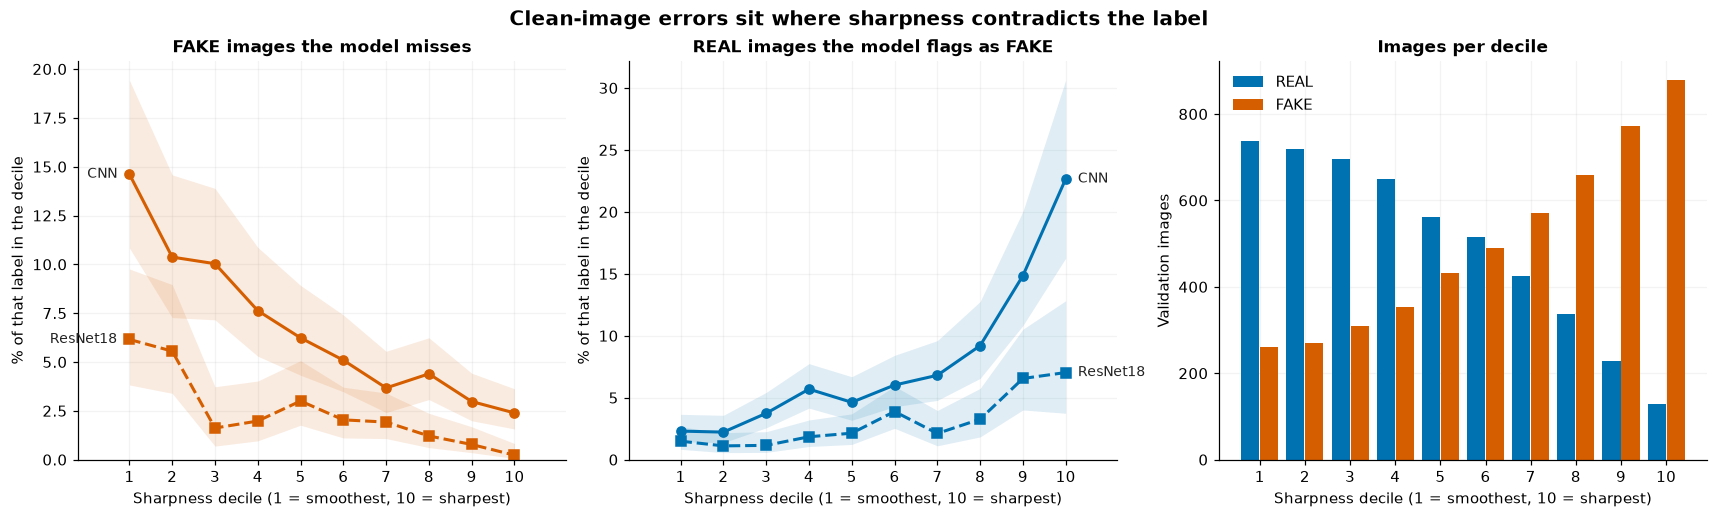

In [24]:
# Add label counts so small groups are visible.
for ax in axes[:2]:
    ax.set_ylabel("% of that label in the decile")
    ax.set_ylim(bottom=0)
    ax.set_xlim(-1.2, 10.2)
n_fake = [(fake_mask & (decile == d)).sum() for d in x]
n_real = [(real_mask & (decile == d)).sum() for d in x]
axes[2].bar(x - 0.21, n_real, width=0.4, color=REAL_C, label="REAL")
axes[2].bar(x + 0.21, n_fake, width=0.4, color=FAKE_C, label="FAKE")
axes[2].legend(frameon=False)
axes[2].set_title("Images per decile")
axes[2].set_ylabel("Validation images")
for ax in axes:
    ax.set_xticks(x, [str(d + 1) for d in x])
    ax.set_xlabel("Sharpness decile (1 = smoothest, 10 = sharpest)")
fig.suptitle("Clean-image errors sit where sharpness contradicts the label", fontsize=13, fontweight="bold")
finish(fig, "01_errors_by_sharpness_decile")


In [25]:
# Check whether the models still separate labels within a sharpness group.
# High AUC within a group means sharpness alone is not the whole decision rule.
auc_within = {m: [roc_auc_score(labels[decile == d], model_logits[m][0][decile == d]) for d in x] for m in MODELS}
auc_sharp_only = roc_auc_score(fake_mask, original_sharpness)


**What we found in the saved run.** The CNN misses **14.6%** of the smoothest fakes but only **2.4%** of the sharpest, and flags **22.7%** of the sharpest real photos versus **2.3%** of the smoothest. ResNet18 makes fewer mistakes, but in the same direction (6.2% → 0.2% missed fakes; 1.5% → 7.0% flagged reals). The training-data observation therefore shows up in the outputs.

**But sharpness is not the whole rule.** Sharpness alone separates REAL from FAKE with ROC-AUC **0.732**. *Within* each decile, where sharpness is held roughly constant, the CNN still reaches ROC-AUC **0.979–0.990** and ResNet18 **0.994–0.999**. Both models use more evidence than global sharpness; sharpness decides mainly *which* images end up on the wrong side. The next sections test what happens when we move sharpness on purpose.


## 2. One dial behind every edit?

The model notebooks studied JPEG, blur, resizing and noise as four separate problems. Here we put them on **one axis**: the median sharpness of the edited images. Each line follows one edit family from the original (black star) through its four strengths; panels split the 5,000 fake and the 5,000 real images and the two models. The vertical axis is always the share of images predicted FAKE, so for fake images it is the detection rate and for real images the false-alarm rate.

To test the idea in the opposite direction we add a **counterfactual that the dataset never contains**: unsharp-mask sharpening (radius 1 px, 25–200 %). If the detectors read sharpness, sharpening should push real photos toward FAKE. The dashed arrows show a second test: blur by 0.6 px (which fools both models) and *then* sharpen again. If the lost evidence is fine detail, re-creating fine detail should restore detection. If all families fall on one shared curve, the edit type does not matter; only how much fine detail it leaves.


In [26]:
# Compare the edit families on a shared sharpness scale.
DIAL_FAMILIES = ["JPEG", "Blur", "Resize", "Noise", "Sharpen"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10.5), sharey=True, layout="constrained")


In [27]:
# Follow each edit family across the same sharpness axis.
for r, model in enumerate(MODELS):
    for c, (mask, name) in enumerate(((fake_mask, "FAKE"), (real_mask, "REAL"))):
        ax = axes[r, c]
        point = lambda i: (np.median(image_stats[i, mask, sharpness_column]), 100 * np.mean(predicted_fake(model, i)[mask]))
        for family in DIAL_FAMILIES:
            pts = np.array([point(i) for i in [0] + cond(family)])
            ax.plot(pts[:, 0], pts[:, 1], "-o", color=FAMILY_COLORS[family], lw=2, ms=6, zorder=3)
            last = CONDITIONS[cond(family)[-1]]["label"]
            below = family == "JPEG" or (family != "Sharpen" and pts[-1, 1] > 90)
            ax.annotate(f"{family} {last}", pts[-1], xytext=(-6, -13) if family == "JPEG" else ((10, -24) if below else (6, 4)),
                        textcoords="offset points", ha="right" if family == "JPEG" else "left", fontsize=8.5, color=INK,
                        path_effects=[pe.withStroke(linewidth=3, foreground="white")])
        x0, y0 = point(0)
        ax.plot(x0, y0, marker="*", ms=17, color="black", zorder=5)
        ax.annotate("Original", (x0, y0), xytext=(-10, 10), textcoords="offset points", ha="right", fontsize=9, fontweight="bold")
        start = point(cond("Blur", 2))
        for i in cond("Blur→Sharpen"):
            end = point(i)
            ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", ls="--", lw=1.6, color=FAMILY_COLORS["Sharpen"]), zorder=4)
            ax.annotate(f"→ {CONDITIONS[i]['value']}%", end, xytext=(5, -11), textcoords="offset points",
                        fontsize=8, color=INK, style="italic", path_effects=[pe.withStroke(linewidth=3, foreground="white")])
        ax.axhline(50, color=MUTED, lw=0.8, ls=":")
        ax.set_title(f"{model} · {name} images (n = {mask.sum():,})")
        ax.set_ylim(-3, 103)
        if c == 0:
            ax.set_ylabel("% predicted FAKE")
        if r == 1:
            ax.set_xlabel("Median sharpness of the edited images (log₁₀ Laplacian variance) → more fine detail")


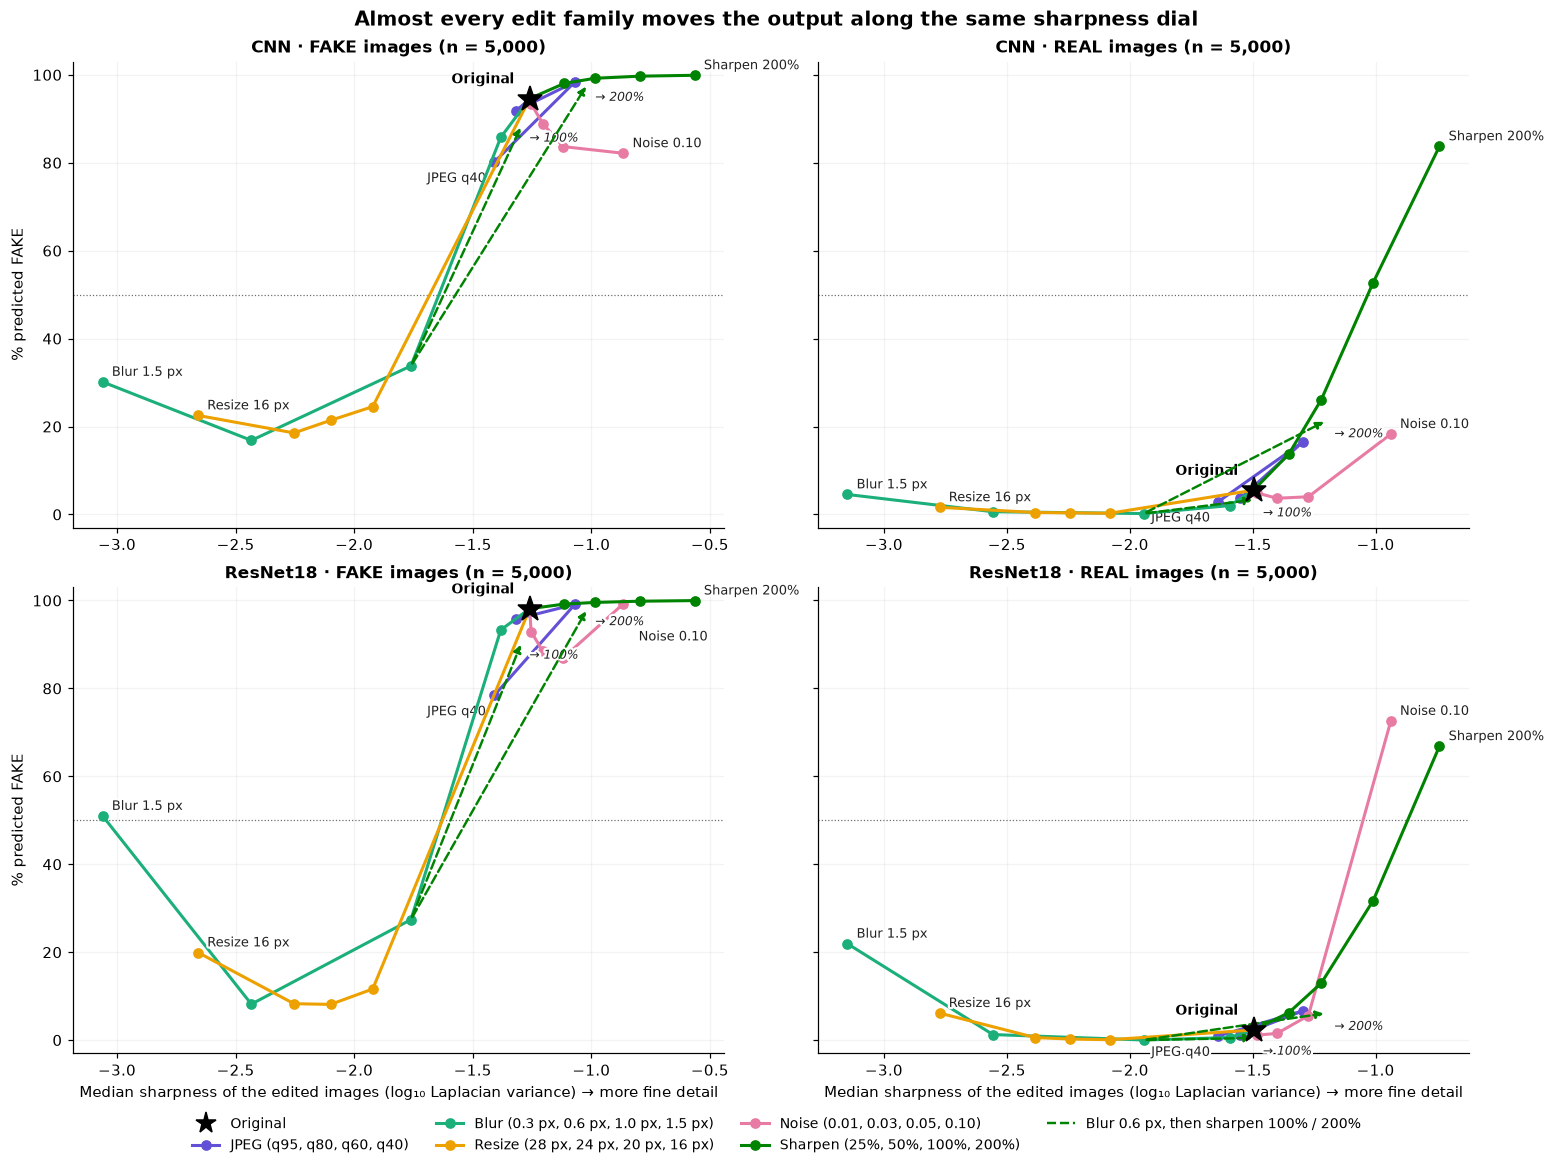

In [28]:
# Add the key and show the completed comparison.
fig.legend(
    handles=[Line2D([], [], marker="*", ms=14, ls="", color="black", label="Original")]
    + [Line2D([], [], marker="o", color=FAMILY_COLORS[f], lw=2, label=f"{f} ({', '.join(CONDITIONS[i]['label'] for i in cond(f))})") for f in DIAL_FAMILIES]
    + [Line2D([], [], ls="--", color=FAMILY_COLORS["Sharpen"], lw=1.6, label="Blur 0.6 px, then sharpen 100% / 200%")],
    loc="outside lower center", ncols=4, frameon=False, fontsize=9,
)
fig.suptitle("Almost every edit family moves the output along the same sharpness dial", fontsize=13, fontweight="bold")
finish(fig, "02_sharpness_dial")


In [29]:
# Name the conditions used in the follow-up sections.
sharpen200, blur_index = cond("Sharpen", 4), cond("Blur", 2)
restore = cond("Blur→Sharpen", 1)


**What we found in the saved run.** Sharpening, which never occurs in the training data, behaves like the mirror image of blur:

- **CNN:** sharpening real photos by 200 % raises false alarms from 5.5% to **83.7%**; blur 0.6 px leaves 33.8% of fakes detected, and sharpening those blurred fakes again (100 %) brings detection back to **88.6%** with 3.4% false alarms.
- **ResNet18:** sharpening real photos by 200 % raises false alarms from 2.3% to **66.9%**; blur 0.6 px leaves 27.4% of fakes detected, and sharpening those blurred fakes again (100 %) brings detection back to **90.6%** with 0.5% false alarms.

JPEG fits the same dial. Quality 60 *raises* the sharpness score (block edges add fine detail) and raises false alarms; quality 40 smooths more, lowers it and lets more fakes through. The strongest blur and resize settings (1.5 px, 16 px) leave the curve; they produce images far outside anything seen in training.

**The exception is noise on fake images.** Noise raises the sharpness score of fakes as much as moderate sharpening does, but the CNN detects *fewer* of them (down to 82.2%) and ResNet18 dips to 86.9% before recovering. On real photos noise behaves like sharpening and raises false alarms (σ = 0.10: 18.3% CNN, 72.6% ResNet18). So the detectors do not respond to *any* high-frequency energy: random noise seems to partly mask whatever fine texture marks a generated image, while still adding the kind of detail that makes a real photo look generated. The Laplacian score cannot tell these two kinds of detail apart; the models can.

**Interpretation (black-box level).** For both detectors, the amount of fine detail acts like a dial that moves the decision across the threshold, and the effect can be reversed by restoring detail. This does not tell us *where* inside the network that happens; that is a Phase II question.


## 3. Lost information, or a shift in confidence?

A label flip can mean two very different things. Either the edit destroys the evidence that separates real from fake (then REAL and FAKE scores overlap), or it moves *all* scores in the same direction while their order is kept (then the classes stay separable, but the fixed threshold is in the wrong place). Accuracy cannot distinguish the two; the score distributions can.

Each column is one edit family and each tick one strength. For both labels we draw the REAL logit as a box (interquartile range), a thick median line and whiskers from the 5th to the 95th percentile. The dotted line is the decision threshold. The number above each strength is the ROC-AUC, which measures only the ranking and ignores the threshold (1 = perfect ranking, 0.5 = chance).


In [30]:
# Keep the full score distributions; a threshold can hide a shared shift.
SHIFT_FAMILIES = ["Blur", "Resize", "Sharpen", "Noise"]
fig, axes = plt.subplots(2, 4, figsize=(17, 9), sharey="row", layout="constrained")
auc_table = {}


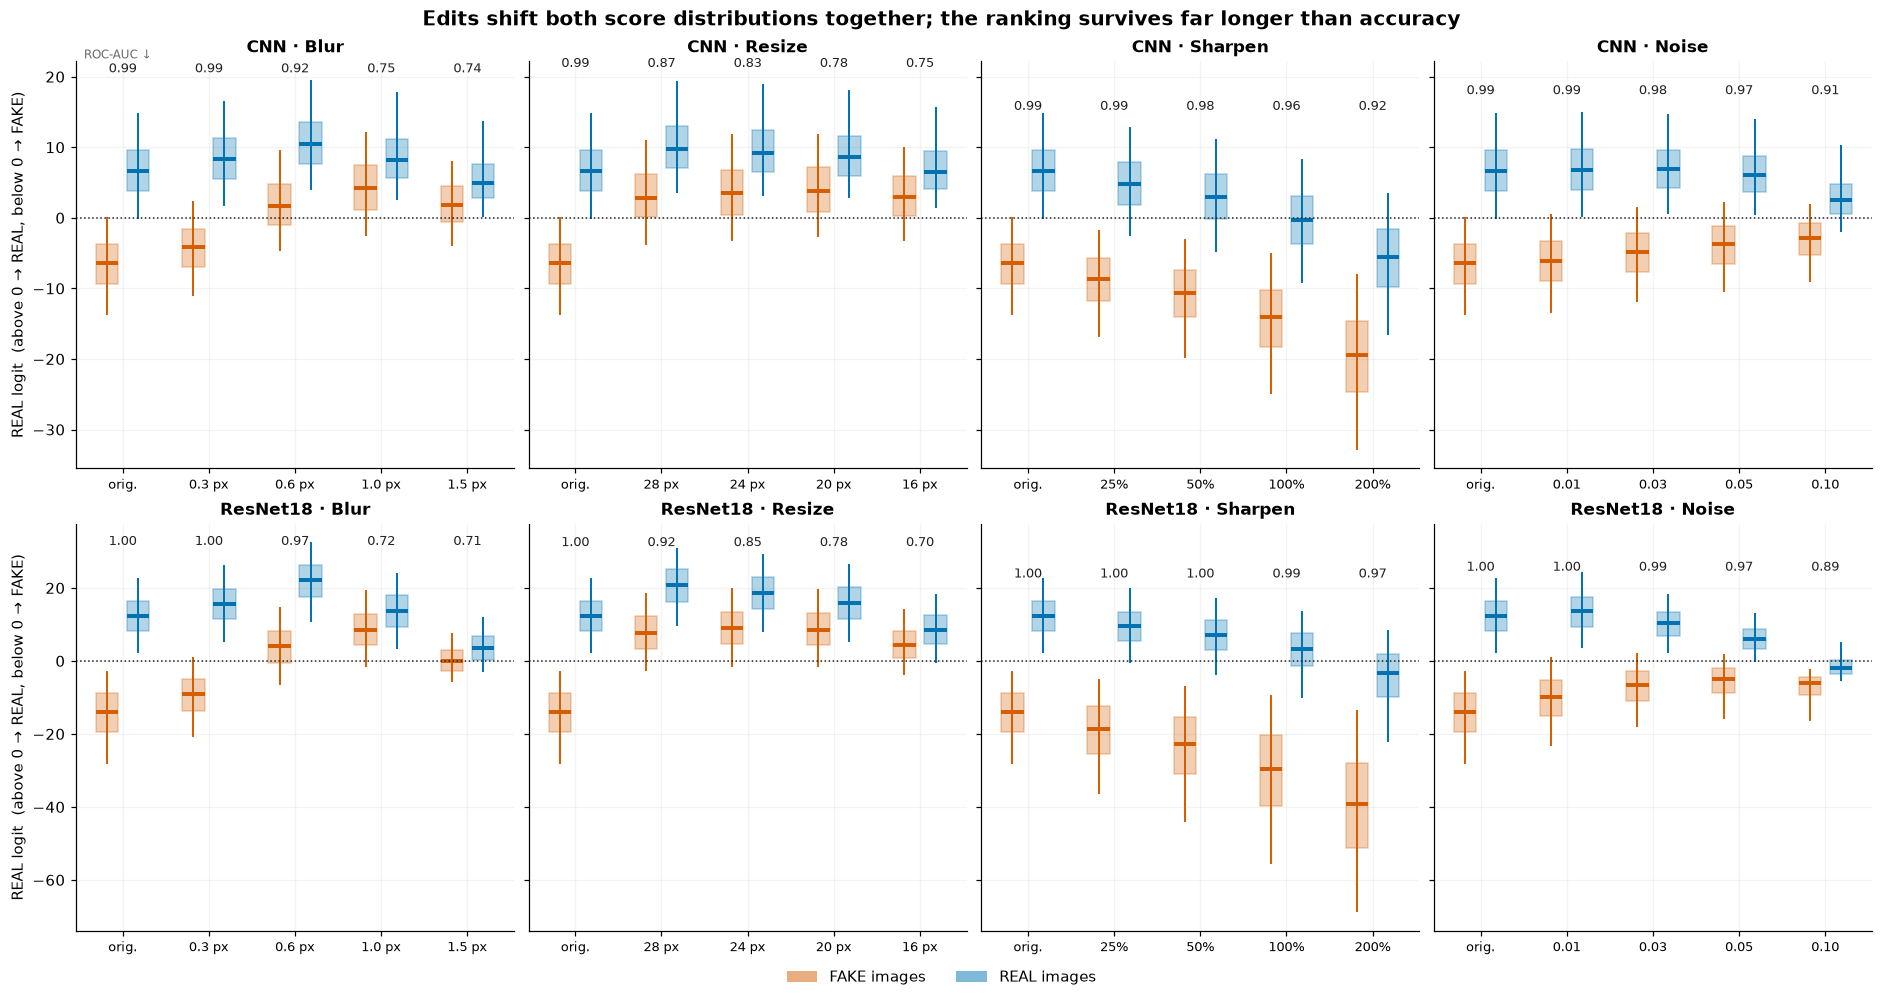

In [31]:
# Draw the two score distributions at every edit strength.
for r, model in enumerate(MODELS):
    for c, family in enumerate(SHIFT_FAMILIES):
        ax = axes[r, c]
        idx = [0] + cond(family)
        top = np.percentile(model_logits[model][idx], 99.0)
        for k, i in enumerate(idx):
            for mask, colour, offset in ((fake_mask, FAKE_C, -0.18), (real_mask, REAL_C, 0.18)):
                # Boxes show the middle half; whiskers show the 5th–95th percentiles.
                q05, q25, q50, q75, q95 = np.percentile(model_logits[model][i][mask], [5, 25, 50, 75, 95])
                ax.vlines(k + offset, q05, q95, color=colour, lw=1.3)
                ax.add_patch(Rectangle((k + offset - 0.13, q25), 0.26, q75 - q25, facecolor=colour, alpha=0.3, edgecolor=colour, lw=1))
                ax.hlines(q50, k + offset - 0.13, k + offset + 0.13, color=colour, lw=2.6)
            # AUC measures ranking, independently of the zero-logit threshold.
            auc = roc_auc_score(labels, model_logits[model][i])
            auc_table[(model, i)] = auc
            ax.text(k, top, f"{auc:.2f}", ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.axhline(0, color=INK, lw=1, ls=":")
        ax.set_xticks(range(len(idx)), ["orig."] + [CONDITIONS[i]["label"] for i in idx[1:]], fontsize=8.5)
        ax.set_title(f"{model} · {family}")
        if c == 0:
            ax.set_ylabel("REAL logit  (above 0 → REAL, below 0 → FAKE)")
axes[0, 0].text(-0.45, axes[0, 0].get_ylim()[1], "ROC-AUC ↓", fontsize=8, color=MUTED, va="bottom")
fig.legend(handles=[Patch(facecolor=FAKE_C, alpha=0.5, label="FAKE images"), Patch(facecolor=REAL_C, alpha=0.5, label="REAL images")],
           loc="outside lower center", ncols=2, frameon=False)
fig.suptitle("Edits shift both score distributions together; the ranking survives far longer than accuracy", fontsize=13, fontweight="bold")
finish(fig, "03_score_shift")


In [32]:
# Keep the resize setting for the agreement plot later.
resize_index = cond("Resize", 1)


**What we found in the saved run.** At blur 0.6 px the median fake logit of the CNN moves from -6.4 to 1.7 and that of ResNet18 from -14.0 to 4.1, past the threshold, while the real images move the same way. The ranking is damaged much less: ROC-AUC is 0.92 (CNN) and 0.97 (ResNet18) at blur 0.6 px, and 0.92 for ResNet18 after resizing to 28 px, where its accuracy is only 55.8%. Sharpening shows the mirror image: both distributions slide toward FAKE while ROC-AUC stays at 0.92 or higher.

So the dominant behaviour is a **shift in confidence for every image**, not a loss of the information that separates the labels. Only the strongest edits (blur ≥ 1 px, resize ≤ 20 px) bring ROC-AUC down toward 0.7, where the evidence itself is going. This is a behavioural statement about the outputs; it does not mean that a different threshold would make the detector reliable, because the right threshold would depend on how the images were processed.


## 4. Does every image respond the same way? Centered ICE curves

The previous plots summarise thousands of images. **Individual conditional expectation (ICE)** curves (Lecture 4) draw one line per image: its output at every strength of an edit. **Centering** each line at its original value (c-ICE) shows the *change* caused by the edit, so images that start with very different confidence become comparable. The thick black line is the average over all images of that label, the partial dependence (PDP). We draw 300 randomly chosen fakes under blur and 300 randomly chosen reals under sharpening.

The colour encodes each image's original **sharpness**. If the size of the reaction depends on how much fine detail an image had to begin with, the colours will sort vertically. Upward means toward REAL. We also check whether **colour saturation** changes the reaction, because the class view in Section 5 points to colour.


In [33]:
# Draw a seeded sample of curves, but calculate the average over all 5,000 images.
rng = np.random.default_rng(2026)
fake_sample = rng.choice(np.flatnonzero(fake_mask), 300, replace=False)
real_sample = rng.choice(np.flatnonzero(real_mask), 300, replace=False)
saturation0 = image_stats[0, :, saturation_column]
fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout="constrained")
spearman = {}


In [34]:
# Each thin line is one image's score change from its original.
for r, model in enumerate(MODELS):
    for c, (family, sample, mask, colour_values, cmap, cbar_label) in enumerate(
        (
            ("Blur", fake_sample, fake_mask, original_sharpness, SEQ_GREEN, "Original sharpness of the fake image (log₁₀)"),
            ("Sharpen", real_sample, real_mask, original_sharpness, SEQ_GREEN, "Original sharpness of the real image (log₁₀)"),
        )
    ):
        ax = axes[r, c]
        idx = [0] + cond(family)
        # Subtract each image's own starting score to compare the size of its response.
        change = model_logits[model][idx] - model_logits[model][0]
        norm = Normalize(*np.percentile(colour_values[mask], [5, 95]))
        for j in sample[np.argsort(colour_values[sample])]:
            ax.plot(range(len(idx)), change[:, j], color=cmap(norm(colour_values[j])), lw=0.8, alpha=0.65)
        # The thick line uses all images of this label, not only the drawn sample.
        ax.plot(range(len(idx)), change[:, mask].mean(1), color="black", lw=3.2, label=f"PDP: average of all {mask.sum():,}")
        ax.axhline(0, color=INK, lw=0.8, ls=":")
        ax.set_xticks(range(len(idx)), ["orig."] + [CONDITIONS[i]["label"] for i in idx[1:]])
        ax.set_ylabel("Change in REAL logit from the original (↑ toward REAL)")
        ax.set_title(f"{model} · {'FAKE images, blur' if family == 'Blur' else 'REAL images, sharpening'}")
        ax.legend(loc="upper left" if family == "Blur" else "lower left", frameon=False)
        fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=cbar_label, shrink=0.85)
        # Check the relationship over the full label group.
        level = cond(family, 2 if family == "Blur" else 3)
        spearman[(model, family)] = spearmanr(colour_values[mask], change[idx.index(level)][mask]).statistic
    spearman[(model, "sat_change")] = spearmanr(saturation0[fake_mask], (model_logits[model][blur_index] - model_logits[model][0])[fake_mask]).statistic
    spearman[(model, "sat_start")] = spearmanr(saturation0[fake_mask], model_logits[model][0][fake_mask]).statistic
    spearman[(model, "sat_end")] = spearmanr(saturation0[fake_mask], model_logits[model][blur_index][fake_mask]).statistic
    spearman[(model, "sharp_start")] = spearmanr(original_sharpness[fake_mask], model_logits[model][0][fake_mask]).statistic
    spearman[(model, "sharp_end")] = spearmanr(original_sharpness[fake_mask], model_logits[model][blur_index][fake_mask]).statistic


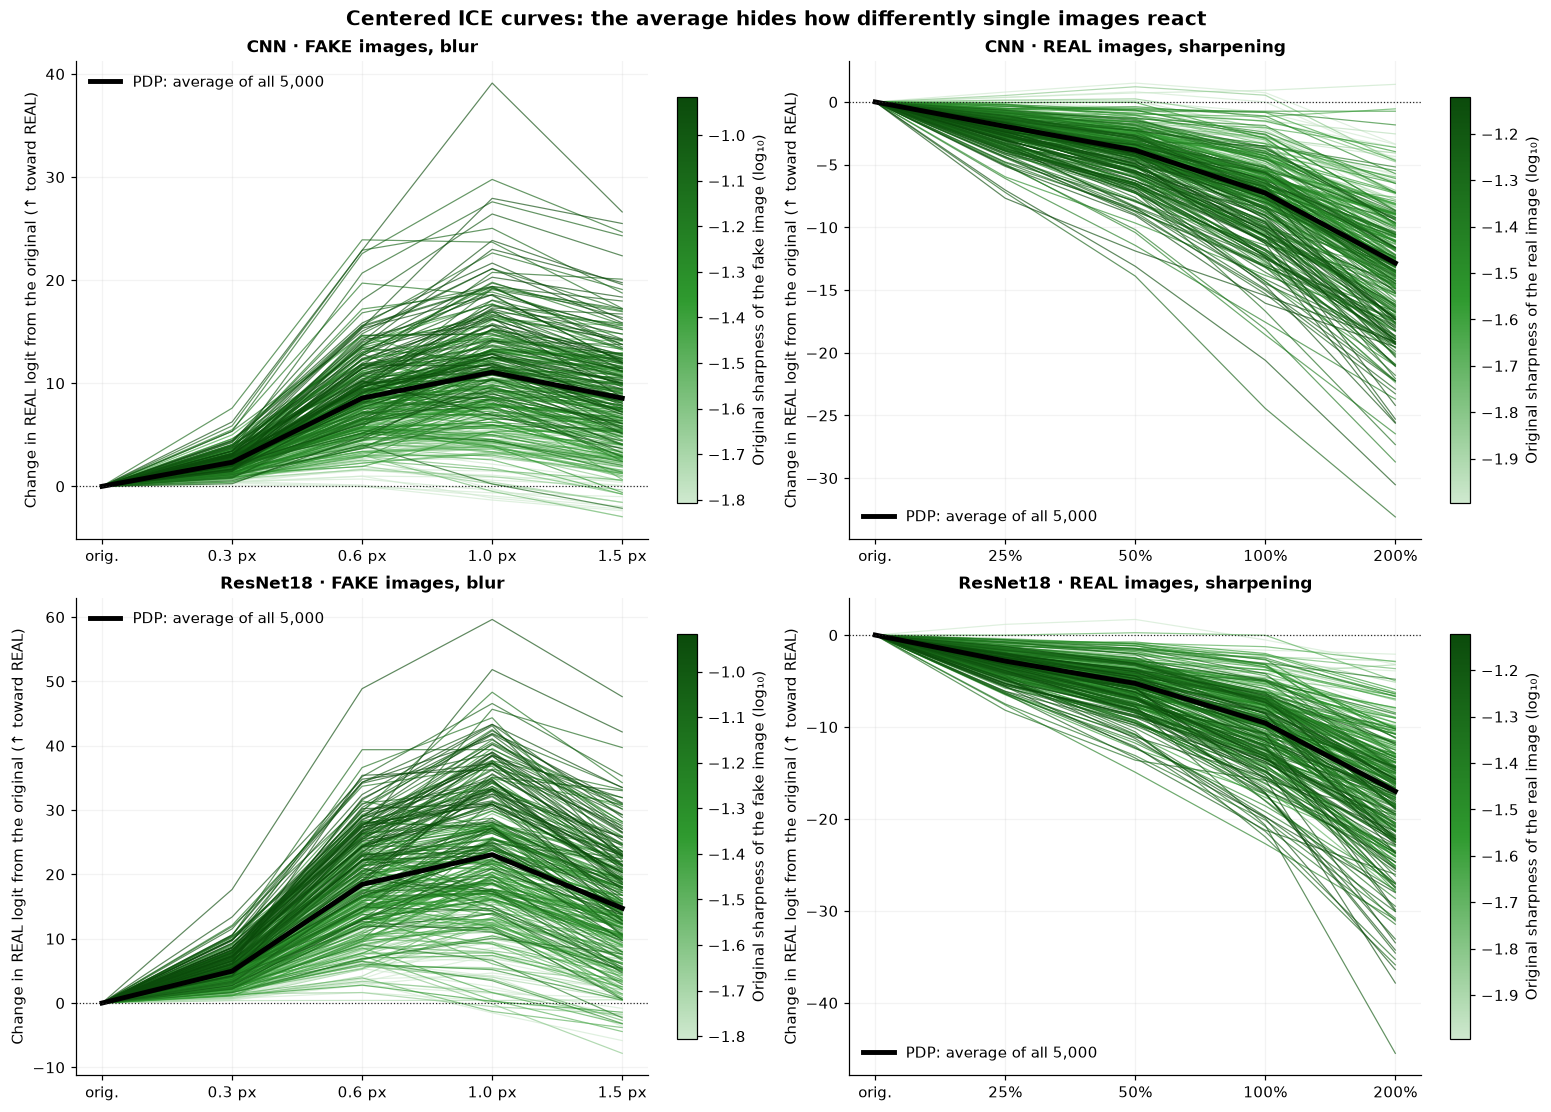

In [35]:
# Finish the shared figure after both models have been drawn.
fig.suptitle("Centered ICE curves: the average hides how differently single images react", fontsize=13, fontweight="bold")
finish(fig, "04_centered_ice")


**What we found in the saved run.** The PDP lines confirm the dial: blur moves fakes toward REAL and sharpening moves real photos toward FAKE in both models. The individual curves show that the size of the effect varies widely, and the colours sort clearly. Across all 5,000 fakes, the Spearman correlation between original sharpness and the logit change at blur 0.6 px is **+0.65** (CNN) and **+0.70** (ResNet18): the more fine detail a fake had, the more blur takes away. For real photos under 100 % sharpening the correlation is -0.58 (CNN) and -0.46 (ResNet18): sharpening amplifies detail that is already there.

This produces a reversal. Sharp fakes start out *more* confidently FAKE (ρ between sharpness and the original logit -0.36 CNN, -0.46 ResNet18), yet after blur they end up *closer to REAL* than smooth fakes (ρ +0.22, +0.29). Their FAKE evidence was mostly fine detail; smooth fakes were detected for other reasons, which blur does not remove.

**Colour behaves differently.** Saturation does not change the *size* of the blur shift (ρ -0.02 CNN, +0.02 ResNet18). For the CNN, however, saturated fakes *start* further on the FAKE side (ρ -0.24) and keep that margin after blur (ρ -0.25). For ResNet18 both correlations are close to zero (-0.07, -0.04). Colour is therefore a candidate *second* cue, mainly for the CNN: it does not resist blur, it provides a head start. Section 5 tests it directly.


## 5. Which fakes survive blur, and why? Object class → colour → counterfactual

The README asked which object classes are hardest. A bar chart of error per class would only restate a metric, so we use the class as the entry point of an investigation instead.

**Step 1: who survives?** After blur 0.6 px, how many fakes of each class are still detected? **Step 2: what do they have in common?** Section 4 suggests colour saturation, and generated images of some classes are far more saturated than the real photos of the same class. **Step 3: test it.** We blur the same images and then *remove colour* (saturation ×0.75 and ×0.5). If colour is the evidence that keeps blurred fakes detected, detection should fall most for the most saturated classes. If a class does not react, its survivors must rely on something else.

The slope chart follows each class through the three steps. Colour encodes how saturated that class's fake images are (darker = more saturated); class names are written at the line ends.


In [36]:
# Spread the class labels a little so they remain readable.
def repel(values, gap):
    """Spread label positions so direct labels do not overlap."""
    order = np.argsort(values)
    placed = np.array(values, float)
    for a, b in zip(order[:-1], order[1:]):
        if placed[b] - placed[a] < gap:
            placed[b] = placed[a] + gap
    return placed


In [37]:
# Follow blur, then the same blur with two levels of desaturation.
chain = [cond("Blur", 2), cond("Blur→Desaturate", 1), cond("Blur→Desaturate", 2)]
chain_labels = ["blur 0.6 px", "+ saturation ×0.75", "+ saturation ×0.5"]
class_saturation = np.array([np.median(saturation0[fake_mask & (objects == o)]) for o in range(10)])
real_class_saturation = np.array([np.median(saturation0[real_mask & (objects == o)]) for o in range(10)])
names = list(BUNDLE["object_names"])
norm = Normalize(class_saturation.min(), class_saturation.max())
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.6), sharey=True, layout="constrained")
survival = {}


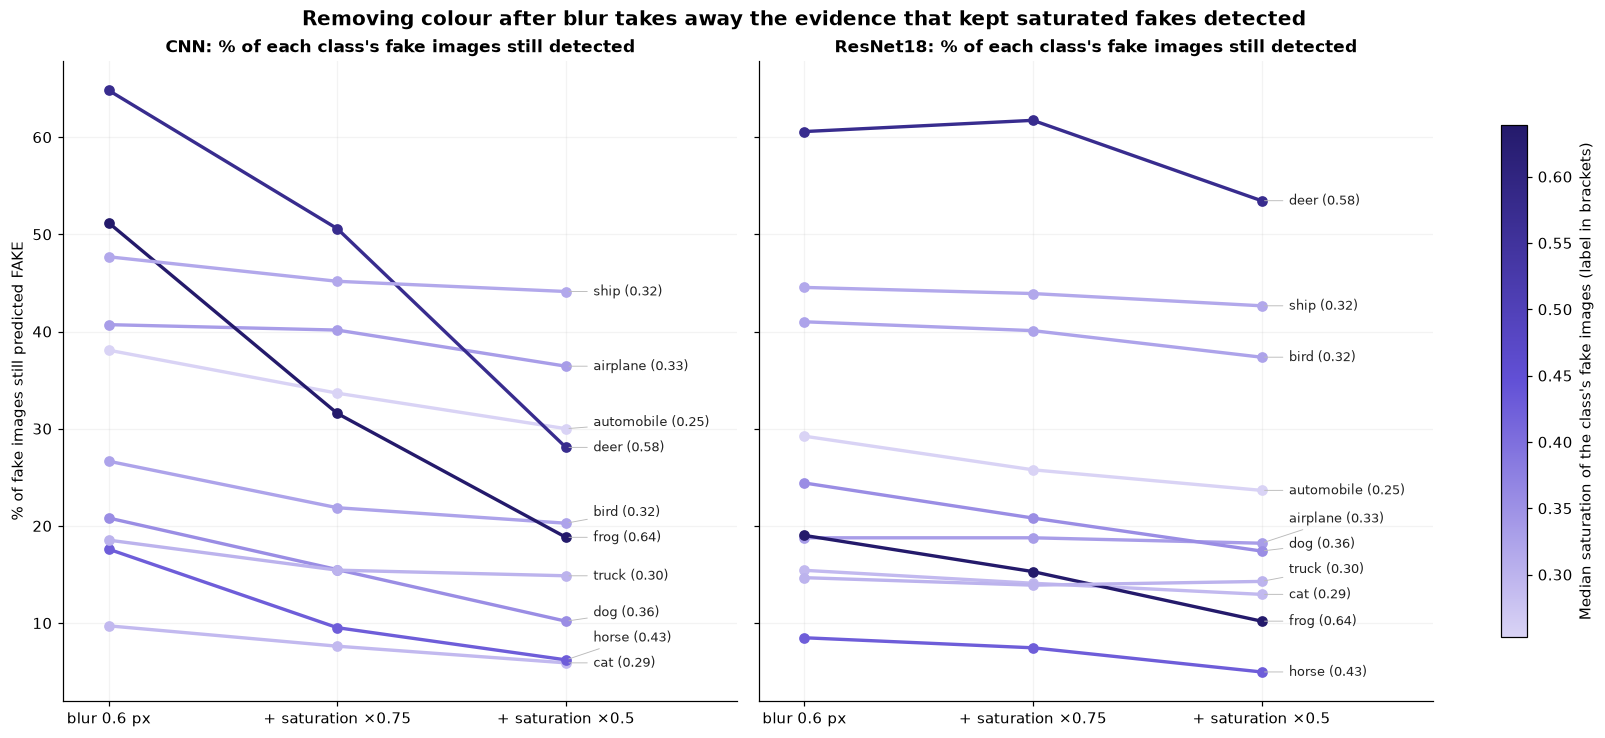

In [38]:
# Track each object class through those three conditions.
for ax, model in zip(axes, MODELS):
    ends = []
    for o in range(10):
        # Follow the same fake images of this class through all three edits.
        mask = fake_mask & (objects == o)
        ys = [100 * np.mean(predicted_fake(model, i)[mask]) for i in chain]
        survival[(model, o)] = ys
        ax.plot(range(3), ys, "-o", color=SEQ_PURPLE(norm(class_saturation[o])), lw=2.2, ms=6)
        ends.append(ys[-1])
    for o, y in zip(range(10), repel(ends, 2.6)):
        ax.annotate(f"{names[o]} ({class_saturation[o]:.2f})", (2, survival[(model, o)][-1]), xytext=(2.12, y), textcoords="data",
                    va="center", fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="-", color="#bbbbbb", lw=0.6))
    ax.set_xticks(range(3), chain_labels)
    ax.set_xlim(-0.2, 2.75)
    ax.set_title(f"{model}: % of each class's fake images still detected")
axes[0].set_ylabel("% of fake images still predicted FAKE")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=SEQ_PURPLE), ax=axes, label="Median saturation of the class's fake images (label in brackets)", shrink=0.8)
fig.suptitle("Removing colour after blur takes away the evidence that kept saturated fakes detected", fontsize=13, fontweight="bold")
finish(fig, "05_class_colour_counterfactual")


In [39]:
# Compare the class-specific drops with saturation and check the colour-only control.
drop = {m: np.array([survival[(m, o)][0] - survival[(m, o)][2] for o in range(10)]) for m in MODELS}
rho_drop = {m: spearmanr(class_saturation, drop[m]).statistic for m in MODELS}
top_cnn = np.argsort(-drop["CNN"])[:2]
flat = [o for o in np.argsort(-np.array([survival[("CNN", o)][2] for o in range(10)]))[:3] if drop["CNN"][o] < 10]
# Colour-only edits check whether desaturation matters without blur.
control = {m: [(CONDITIONS[i]["label"], np.mean(predicted_fake(m, i)[fake_mask]), np.mean(predicted_fake(m, i)[real_mask])) for i in cond("Saturation")] for m in MODELS}


**What we found in the saved run.** For the CNN, the classes that lose most detection when colour is removed are **deer** (65% → 28%) and **frog** (51% → 19%), whose fakes are the most saturated (median 0.58 and 0.64, against 0.30 and 0.34 for the real photos of those classes). Across the ten classes, the drop correlates with saturation at Spearman ρ = +0.75 for the CNN and +0.56 for ResNet18, whose drops are much smaller overall. Classes such as **ship, airplane, automobile** keep part of their detection even without colour, so their survivors rely on something else; the gallery below and Section 6 look at what that is. 

**Control: colour alone barely matters.** On untouched (unblurred) images, changing saturation from ×0.5 to ×1.5 moves fake detection only between 91.7%–95.7% (CNN) and 97.0%–98.2% (ResNet18). Colour is a **secondary cue**: it matters once blur has removed the fine detail that otherwise dominates the decision, and the CNN leans on it much more than ResNet18.


**What these fakes look like.** Each row is one fake from the seeded thumbnail sample (30 per class and label) that the CNN still detects after blur 0.6 px. For each of the two classes that react most to desaturation, and for the least reactive class, we show a contrast pair chosen by a fixed rule: the most saturated survivor that the CNN calls REAL once colour is removed, and the most saturated survivor that stays FAKE. The titles give P(FAKE) for the CNN / ResNet18. Images are enlarged without smoothing; the models see 32×32 pixels.


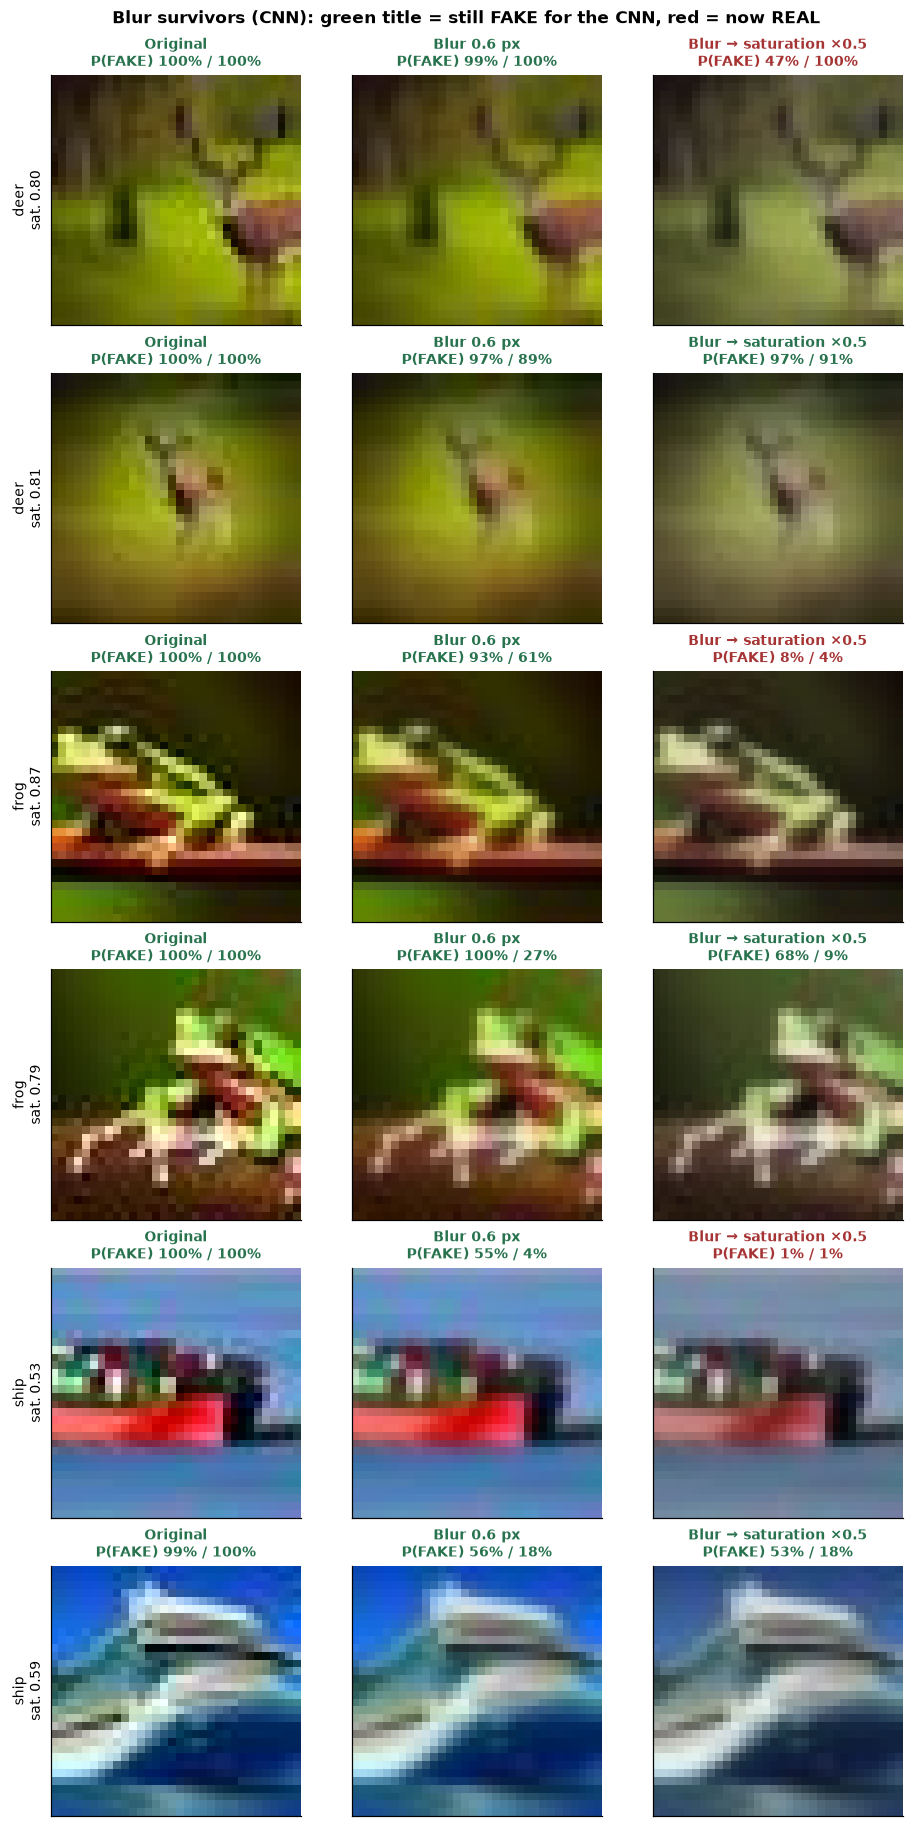

In [40]:
# Pick contrasting examples by a fixed rule, rather than choosing by eye.
gallery_classes = [int(top_cnn[0]), int(top_cnn[1]), int(np.argmin(drop["CNN"]))]
desaturated = cond("Blur→Desaturate", 2)
rows = []
for o in gallery_classes:
    survivors = sorted((i for i in thumbs if objects[i] == o and labels[i] == 0 and predicted_fake("CNN", blur_index)[i]), key=lambda i: -saturation0[i])
    flips = [i for i in survivors if not predicted_fake("CNN", desaturated)[i]]
    stays = [i for i in survivors if predicted_fake("CNN", desaturated)[i]]
    rows += (flips[:1] + stays[:1]) if flips and stays else survivors[:2]
steps = [(0, "Original"), (blur_index, "Blur 0.6 px"), (cond("Blur→Desaturate", 2), "Blur → saturation ×0.5")]
fig, axes = plt.subplots(len(rows), 3, figsize=(8.4, 2.75 * len(rows)), layout="constrained")
for r, i in enumerate(rows):
    for c, (ci, title) in enumerate(steps):
        condition = CONDITIONS[ci]
        image = thumbs[i]
        if condition["family"] != "Original":
            image = modify(image, condition["family"], condition["value"], i)
        ax = axes[r, c]
        ax.imshow(image.transpose(1, 2, 0), interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        pc, pr = p_fake("CNN", ci, i), p_fake("ResNet18", ci, i)
        colour = "#28734e" if pc > 0.5 else "#a63434"
        ax.set_title(f"{title}\nP(FAKE) {pc:.0%} / {pr:.0%}", fontsize=9, color=colour)
        if c == 0:
            ax.set_ylabel(f"{names[objects[i]]}\nsat. {saturation0[i]:.2f}", fontsize=9)
fig.suptitle("Blur survivors (CNN): green title = still FAKE for the CNN, red = now REAL", fontsize=11, fontweight="bold")
finish(fig, "05b_survivor_gallery")


## 6. A map of the fake images: what distinguishes survivors from fooled fakes?

The class view is coarse: within one class some fakes survive blur and others do not. Following the lecture on projections (Lecture 3), we place all 5,000 validation fakes on a 2-D map built only from **model-independent image descriptors**: the six statistics above plus the eight spectral band shares (14 features, standardized). The colour shows what happened after blur 0.6 px: still FAKE for both models, the models disagree, or REAL for both. The map uses no model output; the outcome is painted on afterwards.

**Lecture 3 cautions.** t-SNE keeps local neighbourhoods but not global distances; cluster sizes and gaps between clusters carry no meaning, and the picture depends on perplexity. We therefore show two perplexities and a linear PCA view, and we do **not** cut groups on the t-SNE picture. Groups come from k-means on the 14 standardized descriptors themselves (Lecture 2, clustering), numbered by how often their fakes survive; their numbers are written onto the map.


In [41]:
# Build the map from image measurements only.
fake_index = np.flatnonzero(fake_mask)
band_names = [f"band {k + 1}" for k in range(8)]
features = np.column_stack([image_stats[0, fake_index], np.log10(BUNDLE["bands_original"][fake_index].astype(np.float32) + 1e-6)])
# Put descriptors on comparable scales before measuring distances.
standardized_features = (features - features.mean(0)) / features.std(0)
feature_names = descriptor_names + band_names

survive = {m: predicted_fake(m, blur_index)[fake_index] for m in MODELS}
outcome = np.where(survive["CNN"] & survive["ResNet18"], 0, np.where(survive["CNN"] | survive["ResNet18"], 1, 2))
outcome_names = list(OUTCOME_COLORS)


In [42]:
# Group images in the original descriptor space, not on the t-SNE picture.
kmeans = KMeans(n_clusters=6, n_init=20, random_state=0).fit(standardized_features)
raw_cluster = kmeans.labels_
# Number the groups by survival only after clustering on image properties.
both_rate = np.array([np.mean(outcome[raw_cluster == k] == 0) for k in range(6)])
rank = np.argsort(-both_rate)
cluster = np.empty_like(raw_cluster)
for new, old in enumerate(rank):
    cluster[raw_cluster == old] = new  # cluster 1 = highest share of survivors


In [43]:
# Compare two t-SNE settings with a simple PCA view.
started = time.time()
maps = {
    "t-SNE, perplexity 30": TSNE(perplexity=30, init="pca", learning_rate="auto", random_state=0).fit_transform(standardized_features),
    "t-SNE, perplexity 100": TSNE(perplexity=100, init="pca", learning_rate="auto", random_state=0).fit_transform(standardized_features),
    "PCA (linear)": PCA(n_components=2, random_state=0).fit_transform(standardized_features),
}
print(f"Projections computed in {time.time() - started:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(18, 6.4), layout="constrained")


Projections computed in 20 s


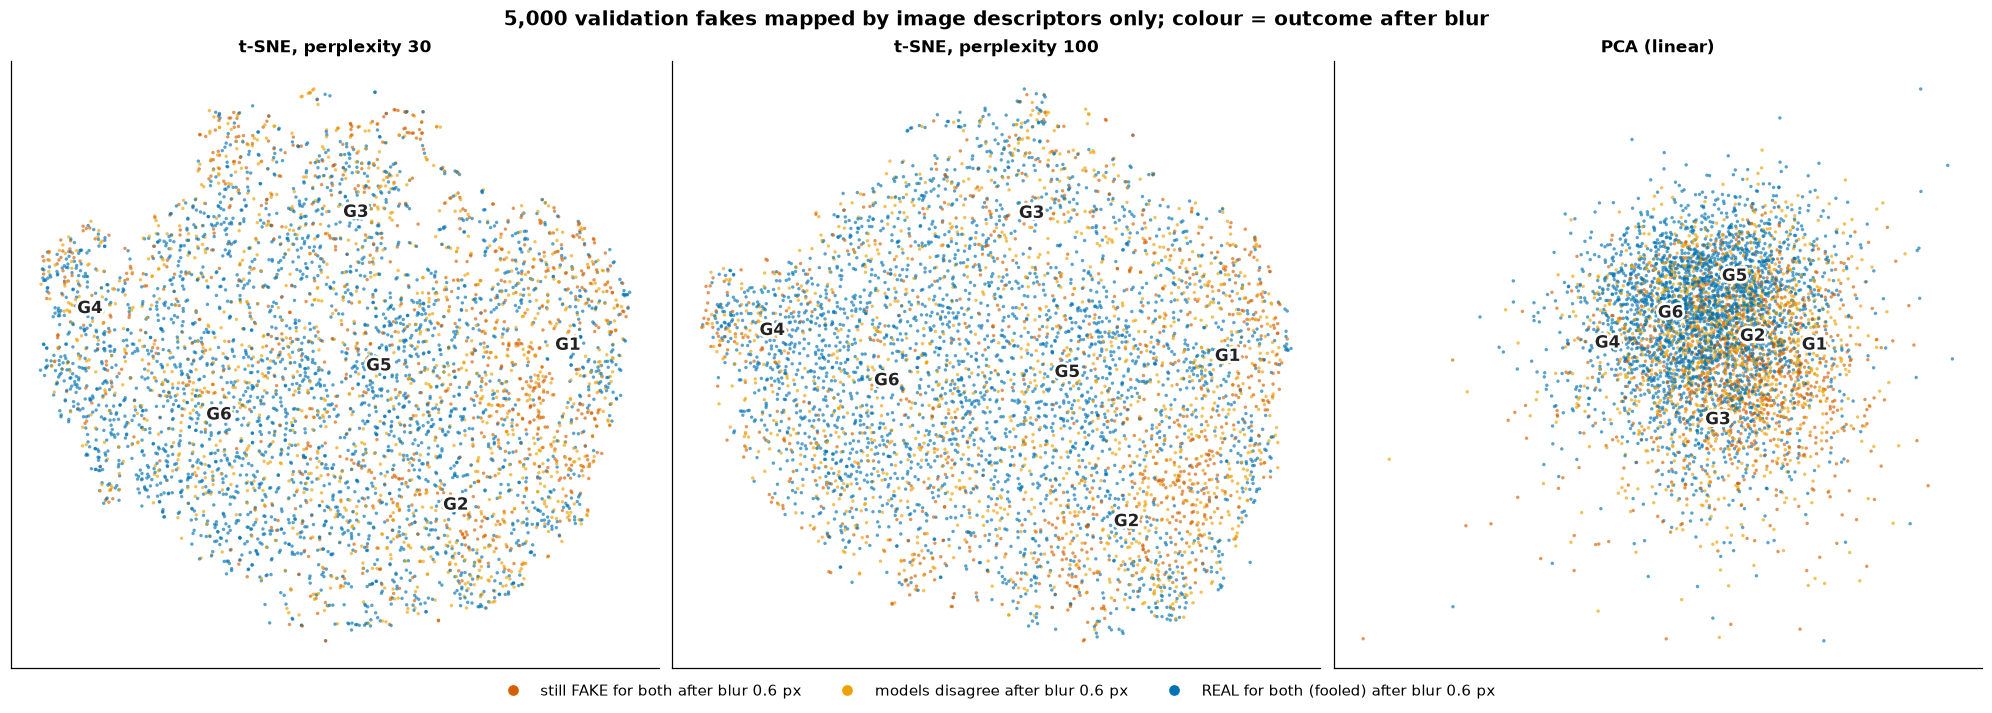

In [44]:
# Colour by the outcome only after calculating the projections.
order = np.random.default_rng(0).permutation(len(fake_index))
for ax, (title, emb) in zip(axes, maps.items()):
    # Mix drawing order so one outcome does not always cover the others.
    ax.scatter(emb[order, 0], emb[order, 1], s=5, c=[OUTCOME_COLORS[outcome_names[o]] for o in outcome[order]], alpha=0.65, lw=0)
    for k in range(6):
        cx, cy = np.median(emb[cluster == k], axis=0)
        ax.text(cx, cy, f"G{k + 1}", fontsize=11, fontweight="bold", ha="center", va="center", color=INK,
                path_effects=[pe.withStroke(linewidth=3.5, foreground="white")])
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=f"{n} after blur 0.6 px") for n, c in OUTCOME_COLORS.items()],
           loc="outside lower center", ncols=3, frameon=False)
fig.suptitle("5,000 validation fakes mapped by image descriptors only; colour = outcome after blur", fontsize=13, fontweight="bold")
finish(fig, "06_fake_map")


**Profiles of the six groups.** Each row is one k-means group (G1 = highest share of survivors). The heatmap shows how far the group's average lies from the average fake, in standard deviations, for each descriptor (orange = higher, purple = lower). The text on the right gives the group size, the share still detected after blur 0.6 px for each model, and the most common object classes in the group. Below, eight thumbnails from the seeded thumbnail sample show members of the most and the least robust group.


In [45]:
# Summarize each group relative to the average fake image.
show = ["brightness", "contrast", "saturation", "log_sharpness", "hf_share", "log_centre_border", "band 1", "band 2", "band 3", "band 5", "band 7", "band 8"]
cols = [feature_names.index(f) for f in show]
# A value of +1 means one standard deviation above the average fake.
profile = np.array([standardized_features[cluster == k][:, cols].mean(0) for k in range(6)])
fig, ax = plt.subplots(figsize=(15, 4.8), layout="constrained")
lim = np.abs(profile).max()
ax.imshow(profile, cmap="PuOr_r", norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
for (r, c), v in np.ndenumerate(profile):
    ax.text(c, r, f"{v:+.1f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.6 * lim else INK)
pretty = {"log_sharpness": "sharpness", "hf_share": "high-freq.\nshare", "log_centre_border": "centre/\nborder", "saturation": "satur-\nation", "brightness": "bright-\nness",
          "band 1": "band 1\n(coarsest)", "band 8": "band 8\n(finest)"}
ax.set_xticks(range(len(show)), [pretty.get(s, s) for s in show], fontsize=8.5)
ax.set_yticks(range(6), [f"G{k + 1}" for k in range(6)])
ax.grid(False)


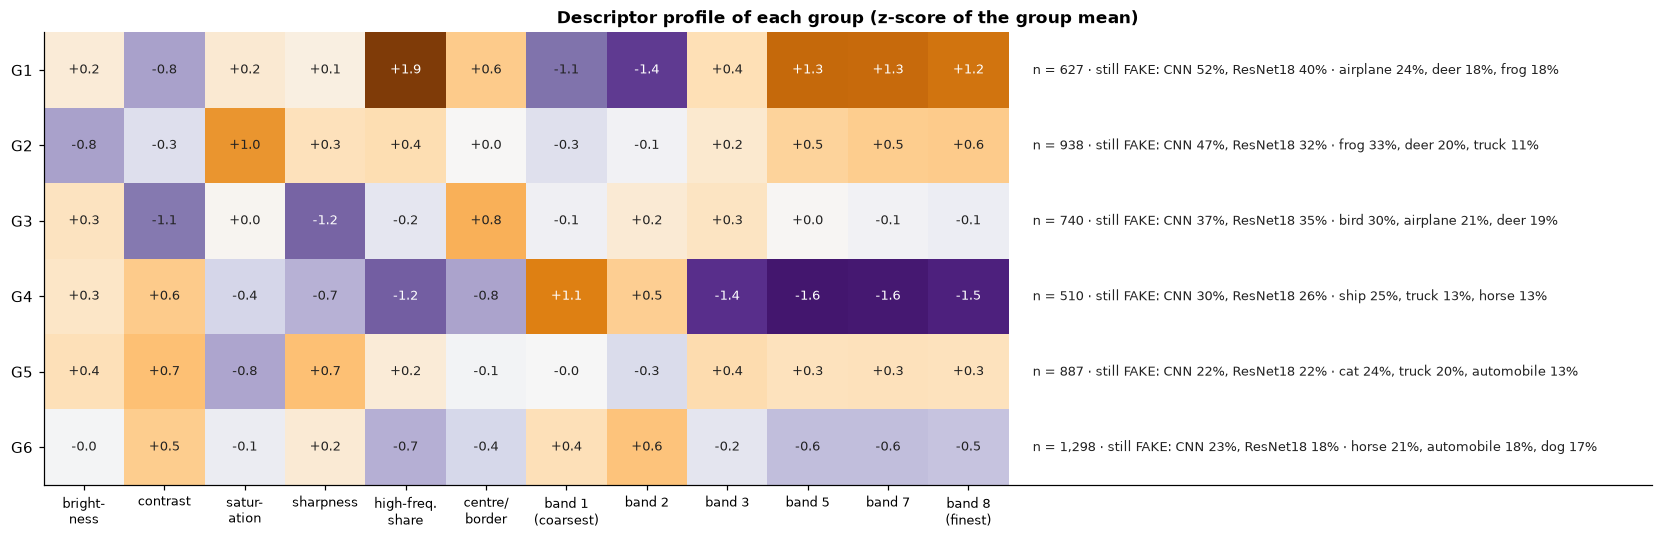

In [46]:
# Add each group's size, detection rates and common object classes.
for k in range(6):
    m = cluster == k
    # Object labels describe the groups; they were not used to build them.
    top = np.bincount(objects[fake_index][m], minlength=10)
    common = ", ".join(f"{names[o]} {100 * top[o] / m.sum():.0f}%" for o in np.argsort(-top)[:3])
    ax.text(len(show) - 0.3, k, f"  n = {m.sum():,} · still FAKE: CNN {pct(np.mean(survive['CNN'][m]), 0)}, ResNet18 {pct(np.mean(survive['ResNet18'][m]), 0)} · {common}",
            va="center", fontsize=8.5, color=INK)
ax.set_xlim(-0.5, len(show) + 7.5)
ax.set_title("Descriptor profile of each group (z-score of the group mean)")
finish(fig, "06b_group_profiles")


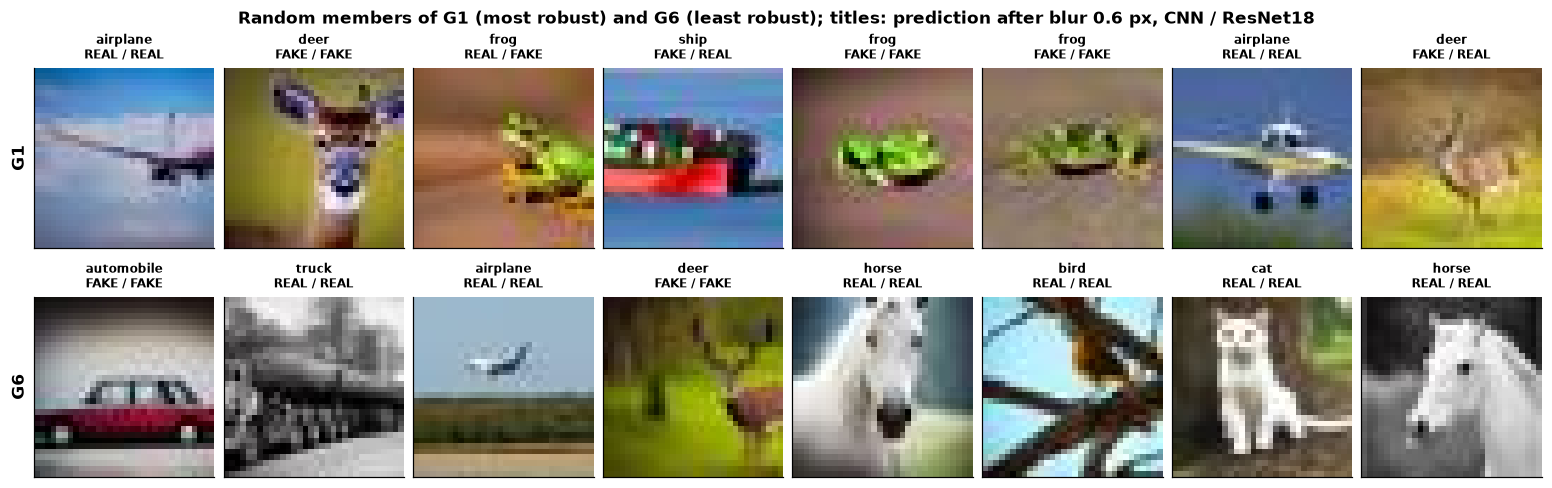

In [47]:
# Show members of the most and least robust groups.
fig, axes = plt.subplots(2, 8, figsize=(14, 4.4), layout="constrained")
for r, k in enumerate((0, 5)):
    members = [i for i in thumbs if labels[i] == 0 and cluster[np.searchsorted(fake_index, i)] == k]
    pick = np.random.default_rng(k).choice(members, min(8, len(members)), replace=False)
    for c, i in enumerate(pick):
        ax = axes[r, c]
        ax.imshow(thumbs[i].transpose(1, 2, 0), interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        # Spell out each prediction before making the thumbnail title.
        cnn_label = "FAKE" if predicted_fake("CNN", blur_index)[i] else "REAL"
        resnet_label = "FAKE" if predicted_fake("ResNet18", blur_index)[i] else "REAL"
        ax.set_title(f"{names[objects[i]]}\n{cnn_label} / {resnet_label}", fontsize=8)
    axes[r, 0].set_ylabel(f"G{k + 1}", fontsize=11, fontweight="bold")
fig.suptitle("Random members of G1 (most robust) and G6 (least robust); titles: prediction after blur 0.6 px, CNN / ResNet18", fontsize=11, fontweight="bold")
finish(fig, "06c_group_examples")


**Reading the figures.** Survival is not spread randomly over the map: the share of fakes still detected by *both* models after blur ranges from 9.5% in G6 to **29.2%** in G1. Both t-SNE runs and the PCA view put the survivors on the same side of the map, so this is not an artefact of one projection.

- **G1** (29.2% survive both): high-frequency share +1.9 SD, band 2 -1.4 SD, band 6 +1.4 SD; most common classes airplane 24%, deer 18%.
- **G2** (24.5%): saturation +1.0 SD, brightness -0.8 SD, finest band +0.6 SD; most common classes frog 33%, deer 20%.
- **G6** (9.5%, least robust): high-frequency share -0.7 SD, band 2 +0.6 SD, band 6 -0.6 SD; most common classes horse 21%, automobile 18%.

In the saved bundle this separates **two kinds of survivors**. One group has a spectrum that is unusually rich in fine detail *relative to its low contrast*: blur removes some of that detail, but enough stays above the coarse structure. The other is the saturated group, dominated by frogs and deer, that Section 5 linked to colour. The easily fooled fakes have the opposite spectral shape, with their energy in the coarse bands. Groups mix object classes, so these are image properties, not only class labels. The descriptors are correlated and k-means groups are a reading aid, not natural categories.


## 7. Do both detectors fail on the same images?

The two models differ in almost everything: architecture, pretraining, input resolution and size. If their failures are caused by properties of the images, they should fail on the **same** images more often than chance; if failures are quirks of each model, the overlap should be close to what independent errors would produce.

Left: every fake image after resizing to 28 px, placed by its CNN logit (x) and ResNet18 logit (y); darker hexagons contain more images, and the quadrant labels count images. Right: for several edits, the overlap of the two models' errors (Jaccard index = images wrong for both / images wrong for at least one), compared with the overlap expected if the two models erred independently at their observed rates. Edits where either model makes fewer than 20 errors of that kind are omitted.


In [48]:
# Compare the two models on the exact same resized fakes.
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), layout="constrained", gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
xs, ys = model_logits["CNN"][resize_index][fake_mask], model_logits["ResNet18"][resize_index][fake_mask]
hb = ax.hexbin(xs, ys, gridsize=45, cmap=SEQ_PURPLE, mincnt=1, bins="log")
fig.colorbar(hb, ax=ax, label="Fake images per hexagon (log scale)")
ax.axhline(0, color=INK, lw=0.9, ls=":")
ax.axvline(0, color=INK, lw=0.9, ls=":")


In [49]:
# Count how many images land in each agreement/disagreement region.
quadrants = {
    (False, False): ("REAL for both", 0.97, 0.97, "right", "top"),
    (True, True): ("FAKE for both", 0.03, 0.03, "left", "bottom"),
    (True, False): ("CNN FAKE, ResNet REAL", 0.03, 0.97, "left", "top"),
    (False, True): ("CNN REAL, ResNet FAKE", 0.97, 0.03, "right", "bottom"),
}
for (cf, rf), (text, tx, ty, ha, va) in quadrants.items():
    n = np.sum(((xs < 0) == cf) & ((ys < 0) == rf))
    ax.text(tx, ty, f"{text}\n{n:,} ({100 * n / len(xs):.1f}%)", transform=ax.transAxes, ha=ha, va=va, fontsize=9,
            path_effects=[pe.withStroke(linewidth=3, foreground="white")])
ax.set_xlabel("CNN REAL logit")
ax.set_ylabel("ResNet18 REAL logit")
ax.set_title("Fake images after resize to 28 px")
ax.grid(False)


In [50]:
# Compare observed error overlap with an independence baseline.
ax = axes[1]
checks = [0, cond("JPEG", 3), blur_index, resize_index, cond("Noise", 4), cond("Sharpen", 3), cond("Saturation", 1)]
rows, ylabels = [], []
for i in checks:
    for mask, kind, wrong_is_fake in ((fake_mask, "fakes missed", False), (real_mask, "reals flagged", True)):
        a = predicted_fake("CNN", i)[mask] == wrong_is_fake
        b = predicted_fake("ResNet18", i)[mask] == wrong_is_fake
        if a.sum() < 20 or b.sum() < 20:
            continue
        both = np.sum(a & b)
        # Independent errors would overlap at the product of the two error rates.
        expected_both = a.mean() * b.mean() * mask.sum()
        # Jaccard divides shared errors by images that fool at least one model.
        observed = both / np.sum(a | b)
        expected = expected_both / (a.sum() + b.sum() - expected_both)
        rows.append((observed, expected, both, expected_both))
        name = "Original" if i == 0 else f"{CONDITIONS[i]['family']} {CONDITIONS[i]['label']}"
        ylabels.append(f"{name} · {kind}")


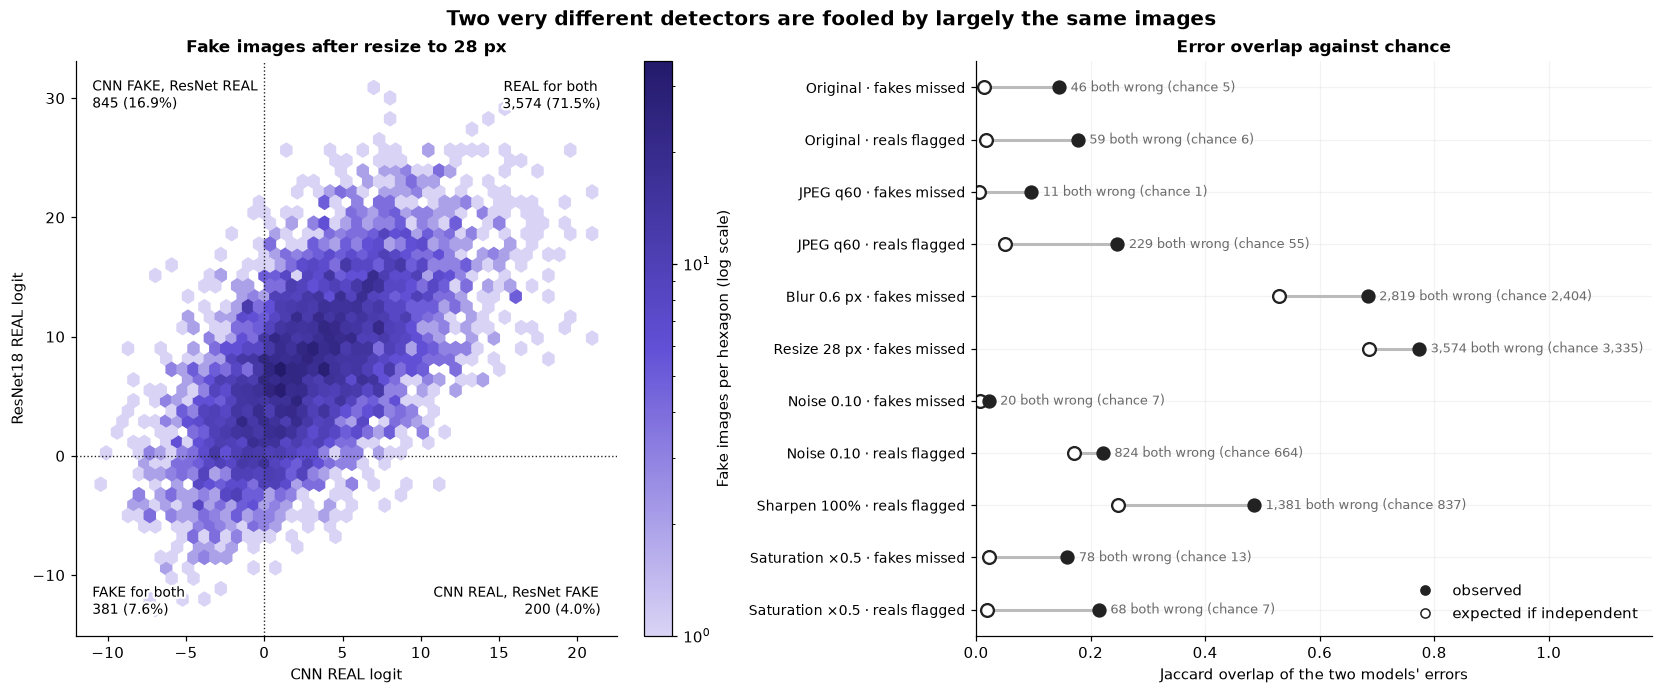

In [51]:
# Join the expected and observed overlap for each condition.
y = np.arange(len(rows))[::-1]
for yy, (observed, expected, both, expected_both) in zip(y, rows):
    ax.plot([expected, observed], [yy, yy], color="#bbbbbb", lw=2, zorder=1)
    ax.scatter(expected, yy, s=70, facecolor="white", edgecolor=INK, lw=1.5, zorder=2)
    ax.scatter(observed, yy, s=70, color=INK, zorder=3)
    ax.text(max(observed, expected) + 0.02, yy, f"{both:,} both wrong (chance {expected_both:,.0f})", va="center", fontsize=8.5, color=MUTED)
ax.set_yticks(y, ylabels, fontsize=9)
ax.set_xlim(0, 1.18)
ax.set_xlabel("Jaccard overlap of the two models' errors")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=INK, label="observed"),
                   Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor=INK, label="expected if independent")],
          loc="lower right", frameon=False)
ax.set_title("Error overlap against chance")
fig.suptitle("Two very different detectors are fooled by largely the same images", fontsize=13, fontweight="bold")
finish(fig, "07_model_agreement")

a = ~predicted_fake("CNN", blur_index)[fake_mask]
b = ~predicted_fake("ResNet18", blur_index)[fake_mask]
noise10 = cond("Noise", 4)


**What we found in the saved run.** Clean errors are rare, but they coincide far more often than chance: 46 fakes are missed by both models where independent errors would give about 5. Under blur 0.6 px, 2,819 fakes fool both models (Jaccard 0.68), and after resizing the two logits are correlated at r = 0.61. The failures are therefore largely **properties of the images**, consistent with the shared sharpness dial, rather than accidents of one architecture. The exception is strong noise (σ = 0.10): ResNet18 flags 72.6% of real photos against 18.3% for the CNN, so the pretrained network reacts to pixel noise much more strongly. That divergence is worth following inside the models in Phase II.


## 8. Phase I findings and questions for Phase II


**What the black-box analysis shows** (10,000 validation images, 29 input conditions, both detectors):

1. **Clean errors follow a training-data difference.** Fakes in CIFAKE are sharper than real photos, and both detectors' mistakes on untouched images concentrate on smooth fakes and sharp real photos (CNN: 22.7% of the sharpest real photos flagged versus 2.3% of the smoothest). Within a fixed sharpness level the models still separate the labels well, so sharpness is not their only evidence.
2. **One dial explains almost every edit.** JPEG, blur, resizing and noise all act through the amount of fine detail they leave. A counterfactual edit the data never contains, sharpening, flags up to 83.7% (CNN) and 66.9% (ResNet18) of real photos, and sharpening blurred fakes restores detection.
3. **The failure is mostly a confidence shift.** Edits move all scores together; ROC-AUC stays high while accuracy collapses (0.92 versus 55.8% for ResNet18 after resizing to 28 px).
4. **Colour is a secondary cue, mostly for the CNN.** Saturated fakes start further on the FAKE side, so many survive blur (deer, frog); desaturating the blurred images removes much of that survival (65% → 28% for deer). On clean images colour alone hardly changes the output.
5. **The sharpest fakes are the most fragile.** Their FAKE evidence is mostly fine detail, so blur moves them furthest. Survivors are either colourful or have a spectrum rich in fine detail relative to their low contrast, and these profiles cut across object classes.
6. **Both detectors fail on largely the same images**, except under strong noise, where ResNet18 is far more sensitive. Noise is also the one edit that adds fine detail to fakes *without* making them look more fake.

**Limits.** These are validation-set observations of one trained run per model, with a fixed 0.5 threshold. The sharpness score is a proxy, and every edit changes more than one property (sharpening also raises edge contrast). Black-box tests show *what* the models respond to, not *how* they compute it.

**Questions for Phase II (opening the box):**

- Where inside each network is fine detail turned into FAKE evidence? (frequency-sensitivity maps, saliency with sanity checks, the CNN's first-layer channel 11 from `phase2/01_cnn_internals.ipynb`)
- Is there a separate colour pathway in the CNN that takes over after blur, and why is it much weaker in ResNet18?
- What keeps blurred ship and bird fakes detected when colour is removed?
- Why does ResNet18 react so much more strongly to pixel noise, and why does noise make fakes look *less* fake when sharpening makes them look more fake?
- Do blurred fakes move into the REAL region of each model's internal representation (embedding trajectories), and when during training did this dependence appear (saved per-epoch checkpoints)?
